<a href="https://colab.research.google.com/github/poojasree-6004/23BDS0124-POOJASREE/blob/main/23BDS0124_EDA_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/countymurders.csv"
df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())
display(df.dtypes.to_frame("Data type"))

Dataset shape: (37349, 21)


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
0,1,2.0,1001,54.05,32216,20.63,15.28,22.33,40.25,167.67,...,29.16,1980,2,0.620810,0.620810,1,1,0,10.38022,0.0
1,2,3.0,1001,53.66,31984,20.19,15.55,22.07,40.36,167.99,...,43.92,1981,1,0.312656,0.937969,1,1,0,10.37299,0.0
2,3,2.0,1001,53.75,32036,19.66,15.73,21.80,40.42,166.63,...,71.41,1982,3,0.936446,0.624298,1,1,0,10.37462,0.0
3,4,7.0,1001,53.78,32056,19.10,15.88,21.53,40.47,176.53,...,72.22,1983,7,2.183679,2.183679,1,1,0,10.37524,0.0
4,5,3.0,1001,53.91,32128,18.54,15.92,21.26,40.51,166.25,...,40.36,1984,2,0.622510,0.933765,1,1,0,10.37748,0.0


Columns: ['rownames', 'arrests', 'countyid', 'density', 'popul', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcincmaint', 'rpcpersinc', 'rpcunemins', 'year', 'murders', 'murdrate', 'arrestrate', 'statefips', 'countyfips', 'execs', 'lpopul', 'execrate']


,Data type
rownames,int64
arrests,float64
countyid,int64
density,float64
popul,int64
perc1019,float64
perc2029,float64
percblack,float64
percmale,float64
rpcincmaint,float64


In [ ]:
dataframe1 = pd.DataFrame({
    "ProductID": range(1, 11),
    "NameofProd": ["Pen", "Book", "Bag", "Bottle", "Pencil", "Ruler", "Eraser", "File", "Marker", "Stapler"],
    "Price": [10, 50, 400, 120, 5, 15, 4, 30, 25, 80]
})
dataframe2 = pd.DataFrame({
    "ProductID": [1, 2, 3, 4, 5, 11, 12, 13, 14, 15],
    "Company_Location": ["Chennai", "Delhi", "Mumbai", "Pune", "Hyderabad",
                         "Kochi", "Jaipur", "Kolkata", "Bengaluru", "Vijayawada"]
})
dataframe3 = pd.DataFrame({
    "ProductID": range(11, 21),
    "NameofProd": ["Pouch", "Tape", "Glue", "Scissors", "Folder", "Crayons", "Paint", "Brush", "Clip", "Diary"],
    "Price": [35, 20, 18, 45, 25, 60, 90, 40, 8, 70]
})

print("Append/concatenate dataframe1 and dataframe3:")
display(pd.concat([dataframe1, dataframe3], ignore_index=True))
print("Concatenate dataframe1 and dataframe3 side-by-side:")
display(pd.concat([dataframe1, dataframe3], axis=1))
print("Merge:")
display(dataframe1.merge(dataframe2, on="ProductID", how="inner"))
print("Inner join:")
display(dataframe1.merge(dataframe2, on="ProductID", how="inner"))
print("Left join:")
display(dataframe1.merge(dataframe2, on="ProductID", how="left"))
print("Right join:")
display(dataframe1.merge(dataframe2, on="ProductID", how="right"))
print("Full outer join:")
display(dataframe1.merge(dataframe2, on="ProductID", how="outer"))

Append/concatenate dataframe1 and dataframe3:


,ProductID,NameofProd,Price
0,1,Pen,10
1,2,Book,50
2,3,Bag,400
3,4,Bottle,120
4,5,Pencil,5
5,6,Ruler,15
6,7,Eraser,4
7,8,File,30
8,9,Marker,25
9,10,Stapler,80


Concatenate dataframe1 and dataframe3 side-by-side:


,ProductID,NameofProd,Price,ProductID,NameofProd,Price
0,1,Pen,10,11,Pouch,35
1,2,Book,50,12,Tape,20
2,3,Bag,400,13,Glue,18
3,4,Bottle,120,14,Scissors,45
4,5,Pencil,5,15,Folder,25
5,6,Ruler,15,16,Crayons,60
6,7,Eraser,4,17,Paint,90
7,8,File,30,18,Brush,40
8,9,Marker,25,19,Clip,8
9,10,Stapler,80,20,Diary,70


Merge:


,ProductID,NameofProd,Price,Company_Location
0,1,Pen,10,Chennai
1,2,Book,50,Delhi
2,3,Bag,400,Mumbai
3,4,Bottle,120,Pune
4,5,Pencil,5,Hyderabad


... (4 outputs left out)

Right join:


,ProductID,NameofProd,Price,Company_Location
0,1,Pen,10.0,Chennai
1,2,Book,50.0,Delhi
2,3,Bag,400.0,Mumbai
3,4,Bottle,120.0,Pune
4,5,Pencil,5.0,Hyderabad
5,11,NaN,NaN,Kochi
6,12,NaN,NaN,Jaipur
7,13,NaN,NaN,Kolkata
8,14,NaN,NaN,Bengaluru
9,15,NaN,NaN,Vijayawada


Full outer join:


,ProductID,NameofProd,Price,Company_Location
0,1,Pen,10.0,Chennai
1,2,Book,50.0,Delhi
2,3,Bag,400.0,Mumbai
3,4,Bottle,120.0,Pune
4,5,Pencil,5.0,Hyderabad
5,6,Ruler,15.0,NaN
6,7,Eraser,4.0,NaN
7,8,File,30.0,NaN
8,9,Marker,25.0,NaN
9,10,Stapler,80.0,NaN


In [ ]:
Fname = np.array([1234, 12, 45, 67, 23, 89, 34, 56, 78, 90], dtype=float)

# Range [-3, +3] and [-1, +1] using min-max scaling
min_v, max_v = Fname.min(), Fname.max()
scaled_0_1 = (Fname - min_v) / (max_v - min_v)
scaled_minus1_1 = scaled_0_1 * 2 - 1
scaled_minus3_3 = scaled_0_1 * 6 - 3

# Z-score and decimal scaling
z_score = (Fname - Fname.mean()) / Fname.std(ddof=0)
decimal_scale = Fname / (10 ** len(str(int(np.max(np.abs(Fname))))))

print("Original:", Fname)
print("Min-max [0, 1]:", scaled_0_1)
print("Scaled [-1, 1]:", scaled_minus1_1)
print("Scaled [-3, 3]:", scaled_minus3_3)
print("Z-score:", z_score)
print("Decimal scaling:", decimal_scale)

Original: [1234.   12.   45.   67.   23.   89.   34.   56.   78.   90.]
Min-max [0, 1]: [1.         0.         0.02700491 0.04500818 0.00900164 0.06301146
 0.01800327 0.03600655 0.05400982 0.06382979]
Scaled [-1, 1]: [ 1.         -1.         -0.94599018 -0.90998363 -0.98199673 -0.87397709
 -0.96399345 -0.92798691 -0.89198036 -0.87234043]
Scaled [-3, 3]: [ 3.         -3.         -2.83797054 -2.7299509  -2.94599018 -2.62193126
 -2.89198036 -2.78396072 -2.67594108 -2.61702128]
Z-score: [ 2.99227517 -0.4534092  -0.36035881 -0.29832521 -0.42239241 -0.23629161
 -0.39137561 -0.32934201 -0.26730841 -0.2334719 ]
Decimal scaling: [0.1234 0.0012 0.0045 0.0067 0.0023 0.0089 0.0034 0.0056 0.0078 0.009 ]


In [ ]:
display(df.head(10))
display(df.tail(10))
print("Rows, columns:", df.shape)
print("Column names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nSummary statistics:")
display(df.describe(include="all").T)
print("\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print("Total missing values:", int(df.isna().sum().sum()))
print("\nRows containing at least one missing value:")
display(df[df.isna().any(axis=1)].head(10))


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
0,1,2.0,1001,54.05,32216,20.63,15.28,22.33,40.25,167.67,...,29.16,1980,2,0.620810,0.620810,1,1,0,10.38022,0.0
1,2,3.0,1001,53.66,31984,20.19,15.55,22.07,40.36,167.99,...,43.92,1981,1,0.312656,0.937969,1,1,0,10.37299,0.0
2,3,2.0,1001,53.75,32036,19.66,15.73,21.80,40.42,166.63,...,71.41,1982,3,0.936446,0.624298,1,1,0,10.37462,0.0
3,4,7.0,1001,53.78,32056,19.10,15.88,21.53,40.47,176.53,...,72.22,1983,7,2.183679,2.183679,1,1,0,10.37524,0.0
4,5,3.0,1001,53.91,32128,18.54,15.92,21.26,40.51,166.25,...,40.36,1984,2,0.622510,0.933765,1,1,0,10.37748,0.0
5,6,1.0,1001,54.11,32248,18.06,15.87,20.96,40.45,153.12,...,44.54,1985,2,0.620193,0.310097,1,1,0,10.38121,0.0
6,7,1.0,1001,55.18,32888,17.68,15.66,20.72,40.41,151.56,...,38.35,1986,4,1.216249,0.304062,1,1,0,10.40086,0.0
7,8,2.0,1001,55.81,33264,17.40,15.33,20.49,40.43,141.68,...,35.20,1987,1,0.300625,0.601251,1,1,0,10.41223,0.0
8,9,0.0,1001,56.43,33632,17.25,14.93,20.31,40.42,148.90,...,27.07,1988,0,0.000000,0.000000,1,1,0,10.42323,0.0
9,10,5.0,1001,57.03,33992,17.02,14.55,20.12,40.46,156.56,...,34.70,1989,3,0.882561,1.470934,1,1,0,10.43388,0.0


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
37339,37340,0.0,56045,3.030000,7254,15.56000,12.310000,0.070000,41.01000,73.040,...,66.880,1987,0,0.0,0.00000,56,45,0,8.889308,0.0
37340,37341,0.0,56045,2.850000,6842,15.54000,11.590000,0.060000,41.26000,82.910,...,44.840,1988,0,0.0,0.00000,56,45,0,8.830835,0.0
37341,37342,0.0,56045,2.780000,6676,15.69000,10.950000,0.060000,41.65000,83.120,...,42.770,1989,0,0.0,0.00000,56,45,0,8.806274,0.0
37342,37343,0.0,56045,2.750000,6591,15.93000,10.730000,0.060000,42.01000,76.600,...,34.470,1990,0,0.0,0.00000,56,45,0,8.793460,0.0
37343,37344,0.0,56045,2.710000,6507,16.15000,10.480000,0.060000,42.35000,86.610,...,41.100,1991,0,0.0,0.00000,56,45,0,8.780634,0.0
37344,37345,0.0,56045,2.680000,6430,16.35000,10.260000,0.060000,42.67000,95.540,...,54.190,1992,0,0.0,0.00000,56,45,0,8.768730,0.0
37345,37346,1.0,56045,2.708031,6493,16.67950,9.610350,0.077006,50.13091,107.260,...,42.904,1993,0,0.0,1.54012,56,45,0,8.778480,0.0
37346,37347,0.0,56045,2.736391,6561,16.79622,9.510745,0.030483,50.16004,98.550,...,39.150,1994,0,0.0,0.00000,56,45,0,8.788898,0.0
37347,37348,0.0,56045,2.730135,6546,17.01803,9.563092,0.076383,50.18332,106.928,...,38.048,1995,0,0.0,0.00000,56,45,0,8.786610,0.0
37348,37349,0.0,56045,2.733472,6554,16.90571,9.642966,0.076289,50.13732,116.116,...,40.194,1996,0,0.0,0.00000,56,45,0,8.787830,0.0


Rows, columns: (37349, 21)
Column names: ['rownames', 'arrests', 'countyid', 'density', 'popul', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcincmaint', 'rpcpersinc', 'rpcunemins', 'year', 'murders', 'murdrate', 'arrestrate', 'statefips', 'countyfips', 'execs', 'lpopul', 'execrate']

Data types:
rownames         int64
arrests        float64
countyid         int64
density        float64
popul            int64
perc1019       float64
perc2029       float64
percblack      float64
percmale       float64
rpcincmaint    float64
rpcpersinc     float64
rpcunemins     float64
year             int64
murders          int64
murdrate       float64
arrestrate     float64
statefips        int64
countyfips       int64
execs            int64
lpopul         float64
execrate       float64
dtype: object

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
rownames,37349.0,18675.000000,10781.871939,1.000000,9338.000000,18675.000000,28012.000000,3.734900e+04
arrests,36845.0,6.782250,50.128657,0.000000,0.000000,1.000000,3.000000,2.391000e+03
countyid,37349.0,32921.927173,15528.352966,1001.000000,20105.000000,36065.000000,48049.000000,5.604500e+04
density,37349.0,252.241067,1663.768484,0.050000,17.681580,44.240000,106.600000,5.405877e+04
popul,37349.0,89343.541219,271854.498963,85.000000,13144.000000,28792.000000,66480.000000,9.127751e+06
perc1019,37349.0,15.582640,1.973399,7.080000,14.320000,15.420000,16.730000,3.048458e+01
perc2029,37349.0,14.584615,3.696407,5.617244,12.301700,14.270000,16.200000,4.052000e+01
percblack,37349.0,7.823194,13.287067,0.000000,0.200000,1.450000,8.740000,8.627934e+01
percmale,37349.0,43.350958,3.717612,35.150000,40.900000,41.810000,45.870000,7.804000e+01
rpcincmaint,37346.0,165.450844,97.488961,5.490000,96.250000,145.147500,209.880000,1.306496e+03



Missing values per column:


,Missing values
rownames,0
arrests,504
countyid,0
density,0
popul,0
perc1019,0
perc2029,0
percblack,0
percmale,0
rpcincmaint,3


Total missing values: 1017

Rows containing at least one missing value:


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
266,267,NaN,1035,16.80,14298,15.85,12.67,42.60,39.59,348.65,...,57.25,1991,1,0.699399,NaN,1,35,0,9.567875,0.0
878,879,NaN,1111,34.42,20000,14.89,13.55,23.86,41.05,198.91,...,63.12,1991,2,1.000000,NaN,1,111,0,9.903487,0.0
1030,1031,NaN,1131,15.59,13856,20.00,12.68,69.03,37.89,589.82,...,43.66,1990,1,0.721709,NaN,1,131,0,9.536473,0.0
1031,1032,NaN,1131,15.62,13886,19.85,12.53,69.24,37.89,605.55,...,54.32,1991,3,2.160449,NaN,1,131,0,9.538636,0.0
1112,1113,NaN,2170,1.62,40040,16.90,11.17,0.73,40.74,89.76,...,146.08,1987,1,0.249750,NaN,2,170,0,10.597630,0.0
1275,1276,NaN,5013,9.67,6074,18.63,14.51,27.99,41.60,207.76,...,89.91,1980,1,1.646362,NaN,5,13,0,8.711773,0.0
1377,1378,NaN,5025,13.19,7887,18.07,12.47,15.11,41.59,166.45,...,74.11,1980,0,0.000000,NaN,5,25,0,8.972971,0.0
1793,1794,NaN,5073,18.62,9802,16.50,13.03,38.82,40.22,257.18,...,32.99,1988,1,1.020200,NaN,5,73,0,9.190342,0.0
1836,1837,NaN,5079,23.83,13372,17.40,18.54,35.84,47.19,256.36,...,41.31,1980,1,0.747831,NaN,5,79,0,9.500918,0.0
3434,3435,NaN,8007,2.77,3736,19.33,13.74,0.08,42.58,165.24,...,111.78,1980,1,2.676660,NaN,8,7,0,8.225771,0.0


In [ ]:
clean_df = df.copy()

# Remove rows with any missing values (as requested in one question)
complete_df = clean_df.dropna()
print("Shape after dropping rows with missing values:", complete_df.shape)

# Example mean/median imputation for numerical columns
num_cols = clean_df.select_dtypes(include=np.number).columns.tolist()
if num_cols:
    mean_col = num_cols[0]
    median_col = num_cols[1] if len(num_cols) > 1 else num_cols[0]
    clean_df[mean_col] = clean_df[mean_col].fillna(clean_df[mean_col].mean())
    clean_df[median_col] = clean_df[median_col].fillna(clean_df[median_col].median())
    print("Mean-imputed column:", mean_col)
    print("Median-imputed column:", median_col)

# Mode imputation for any categorical column; if none exist, report it
cat_cols = clean_df.select_dtypes(exclude=np.number).columns.tolist()
if cat_cols:
    cat_col = cat_cols[0]
    mode_values = clean_df[cat_col].mode()
    if not mode_values.empty:
        clean_df[cat_col] = clean_df[cat_col].fillna(mode_values.iloc[0])
    print("Mode-imputed column:", cat_col)
else:
    print("No original categorical columns; county-murders data is numeric.")

# Forward/backward fill, then replace remaining missing values
filled_df = clean_df.ffill().bfill()
for col in filled_df.columns:
    if pd.api.types.is_numeric_dtype(filled_df[col]):
        filled_df[col] = filled_df[col].fillna(0)
    else:
        filled_df[col] = filled_df[col].fillna("Unknown")

# Duplicates, type conversions, renaming and derived column
print("Duplicate rows before removal:", clean_df.duplicated().sum())
clean_df = clean_df.drop_duplicates()
print("Shape after removing duplicates:", clean_df.shape)

if "year" in clean_df.columns:
    clean_df["year"] = clean_df["year"].astype("Int64")
    clean_df["year_group"] = clean_df["year"].astype(str)

clean_df = clean_df.rename(columns={"popul": "population"})
if "murdrate" in clean_df.columns and "population" in clean_df.columns:
    clean_df["murders_per_10000_check"] = clean_df["murdrate"]

display(clean_df.head())


Shape after dropping rows with missing values: (36842, 21)
Mean-imputed column: rownames
Median-imputed column: arrests
No original categorical columns; county-murders data is numeric.
Duplicate rows before removal: 0
Shape after removing duplicates: (37349, 21)


,rownames,arrests,countyid,density,population,perc1019,perc2029,percblack,percmale,rpcincmaint,...,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate,year_group,murders_per_10000_check
0,1,2.0,1001,54.05,32216,20.63,15.28,22.33,40.25,167.67,...,2,0.620810,0.620810,1,1,0,10.38022,0.0,1980,0.620810
1,2,3.0,1001,53.66,31984,20.19,15.55,22.07,40.36,167.99,...,1,0.312656,0.937969,1,1,0,10.37299,0.0,1981,0.312656
2,3,2.0,1001,53.75,32036,19.66,15.73,21.80,40.42,166.63,...,3,0.936446,0.624298,1,1,0,10.37462,0.0,1982,0.936446
3,4,7.0,1001,53.78,32056,19.10,15.88,21.53,40.47,176.53,...,7,2.183679,2.183679,1,1,0,10.37524,0.0,1983,2.183679
4,5,3.0,1001,53.91,32128,18.54,15.92,21.26,40.51,166.25,...,2,0.622510,0.933765,1,1,0,10.37748,0.0,1984,0.622510


In [ ]:
numeric_summary = pd.DataFrame({
    "min": df.select_dtypes(include=np.number).min(),
    "max": df.select_dtypes(include=np.number).max(),
    "range": df.select_dtypes(include=np.number).max() - df.select_dtypes(include=np.number).min(),
    "variance": df.select_dtypes(include=np.number).var(),
    "standard_deviation": df.select_dtypes(include=np.number).std(),
    "IQR": df.select_dtypes(include=np.number).quantile(0.75) - df.select_dtypes(include=np.number).quantile(0.25)
})
display(numeric_summary)

,min,max,range,variance,standard_deviation,IQR
rownames,1.000000,3.734900e+04,3.734800e+04,1.162488e+08,10781.871939,18674.000000
arrests,0.000000,2.391000e+03,2.391000e+03,2.512882e+03,50.128657,3.000000
countyid,1001.000000,5.604500e+04,5.504400e+04,2.411297e+08,15528.352966,27944.000000
density,0.050000,5.405877e+04,5.405872e+04,2.768126e+06,1663.768484,88.918420
popul,85.000000,9.127751e+06,9.127666e+06,7.390487e+10,271854.498963,53336.000000
perc1019,7.080000,3.048458e+01,2.340458e+01,3.894305e+00,1.973399,2.410000
perc2029,5.617244,4.052000e+01,3.490276e+01,1.366343e+01,3.696407,3.898300
percblack,0.000000,8.627934e+01,8.627934e+01,1.765462e+02,13.287067,8.540000
percmale,35.150000,7.804000e+01,4.289000e+01,1.382064e+01,3.717612,4.970000
rpcincmaint,5.490000,1.306496e+03,1.301006e+03,9.504098e+03,97.488961,113.630000


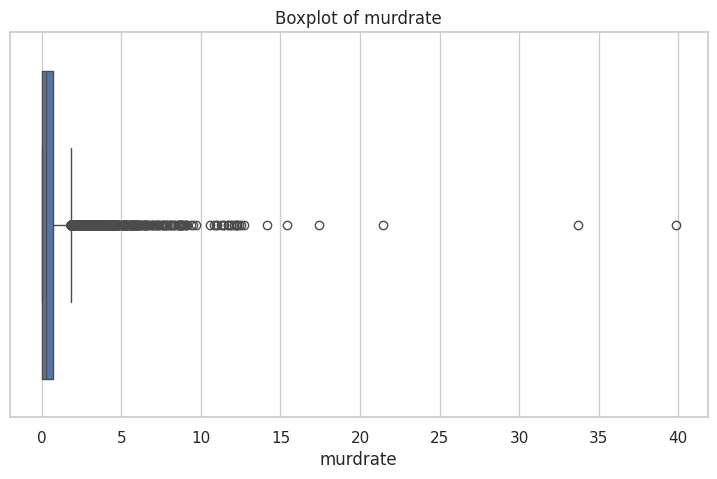

IQR lower/upper bounds: -1.10294115 1.8382352499999999
Number of IQR outliers: 1963


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
3,4,7.0,1001,53.78000,32056,19.10000,15.88000,21.53000,40.47000,176.530,...,72.220,1983,7,2.183679,2.183679,1,1,0,10.375240,0.0
35,36,2.0,1005,27.96000,24744,18.83000,14.39000,44.31000,38.63000,295.360,...,69.170,1981,6,2.424830,0.808277,1,5,0,10.116340,0.0
37,38,3.0,1005,28.02000,24796,18.05000,14.84000,44.15000,38.91000,291.870,...,81.240,1983,5,2.016454,1.209873,1,5,0,10.118440,0.0
72,73,2.0,1011,17.31000,10822,17.62000,15.34000,69.53000,38.72000,414.190,...,46.130,1984,2,1.848087,1.848087,1,11,0,9.289336,0.0
80,81,7.0,1011,17.35000,10844,15.92000,13.71000,72.93000,39.95000,476.280,...,76.290,1992,2,1.844338,6.455183,1,11,0,9.291368,0.0
93,94,9.0,1013,28.58000,22208,16.51000,12.75000,39.75000,38.28000,237.730,...,43.150,1988,6,2.701729,4.052594,1,13,0,10.008210,0.0
126,127,7.0,1017,63.19000,37752,15.79000,14.88000,35.53000,39.90000,146.960,...,31.680,1987,7,1.854206,1.854206,1,17,0,10.538790,0.0
132,133,8.0,1017,62.02479,37054,14.90527,13.61257,36.51427,47.25536,226.284,...,58.128,1993,7,1.889135,2.159011,1,17,0,10.520130,0.0
133,134,6.0,1017,61.70675,36864,14.84918,13.46571,36.80827,47.31445,232.875,...,40.500,1994,8,2.170139,1.627604,1,17,0,10.514990,0.0
171,172,4.0,1023,18.25000,16672,19.34000,14.54000,43.44000,39.35000,339.280,...,46.120,1981,4,2.399232,2.399232,1,23,0,9.721486,0.0


Shape after excluding IQR outliers: (35386, 21)


In [ ]:
target_num = "murdrate" if "murdrate" in df.columns else df.select_dtypes(include=np.number).columns[0]
plt.figure()
sns.boxplot(x=df[target_num])
plt.title(f"Boxplot of {target_num}")
plt.show()

q1, q3 = df[target_num].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df[target_num] < lower) | (df[target_num] > upper)]
print("IQR lower/upper bounds:", lower, upper)
print("Number of IQR outliers:", len(outliers))
display(outliers.head(10))

# Optional filtered data excluding IQR outliers
df_no_extreme = df[df[target_num].between(lower, upper)].copy()
print("Shape after excluding IQR outliers:", df_no_extreme.shape)

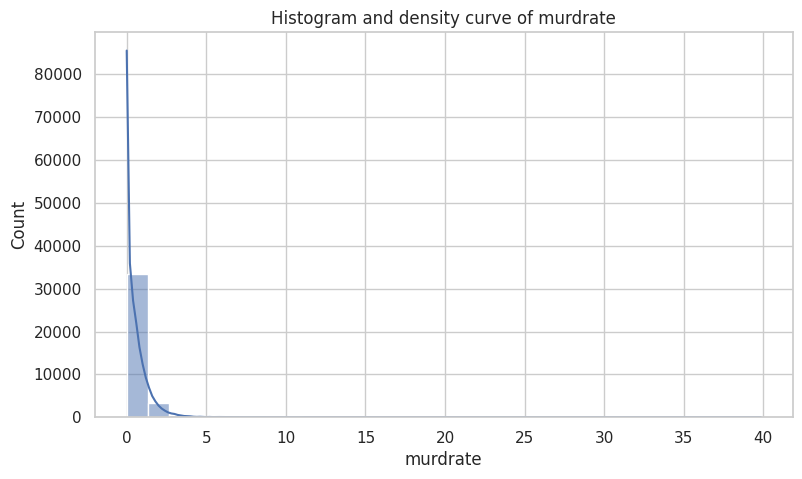

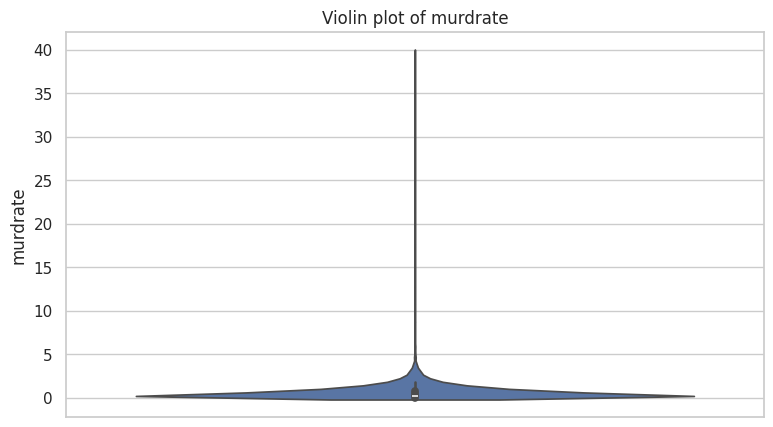

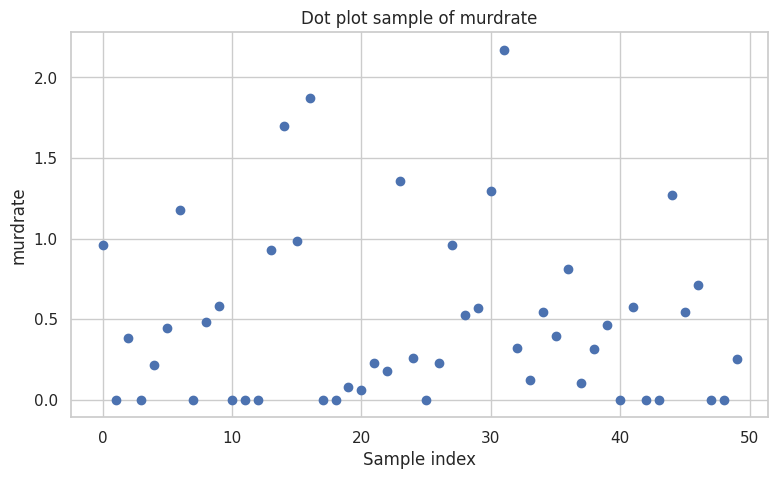

In [ ]:
plt.figure()
sns.histplot(df[target_num].dropna(), bins=30, kde=True)
plt.title(f"Histogram and density curve of {target_num}")
plt.xlabel(target_num)
plt.show()

plt.figure()
sns.violinplot(y=df[target_num].dropna(), inner="box")
plt.title(f"Violin plot of {target_num}")
plt.show()

small_sample = df[target_num].dropna().sample(min(50, df[target_num].notna().sum()), random_state=42)
plt.figure()
plt.plot(range(len(small_sample)), small_sample.to_numpy(), "o")
plt.title(f"Dot plot sample of {target_num}")
plt.xlabel("Sample index")
plt.ylabel(target_num)
plt.show()

,Frequency,Proportion,Percentage
murdrate_group,,,
Low,12450,0.333342,33.334226
Medium,12449,0.333315,33.331548
High,12450,0.333342,33.334226


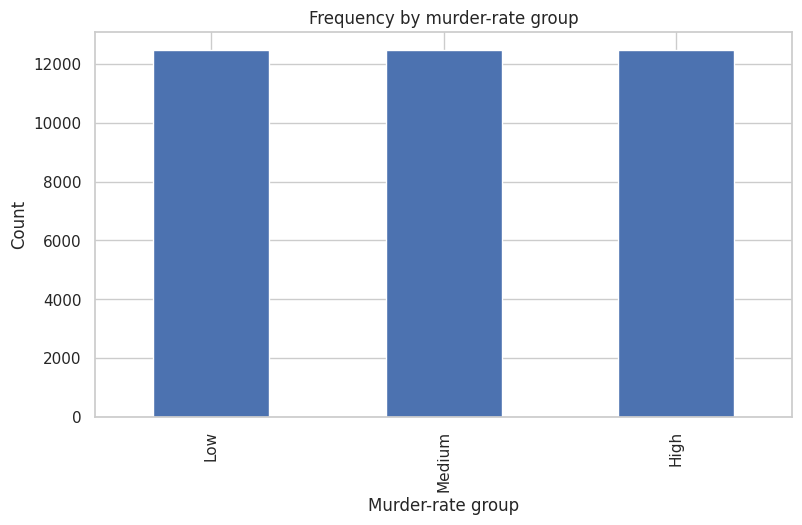

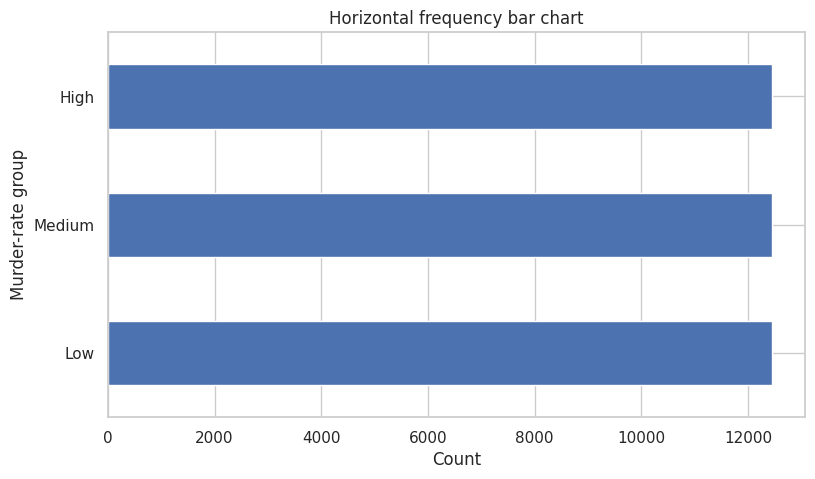

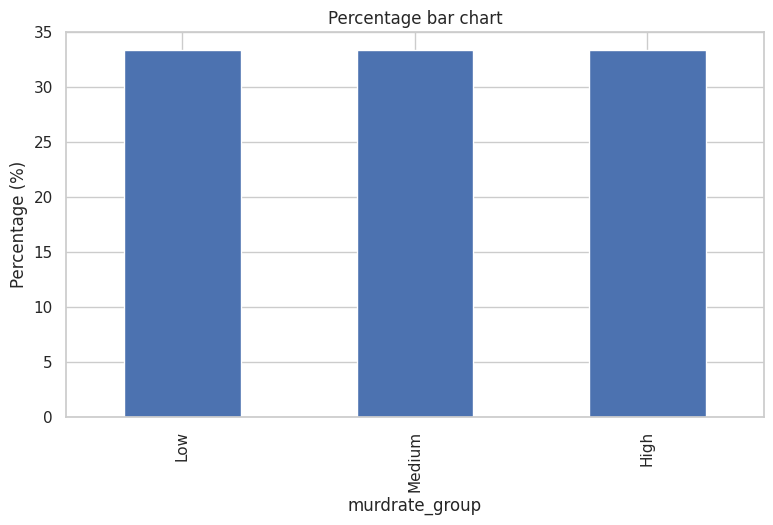

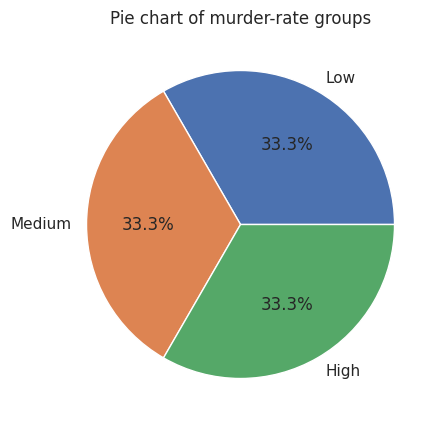

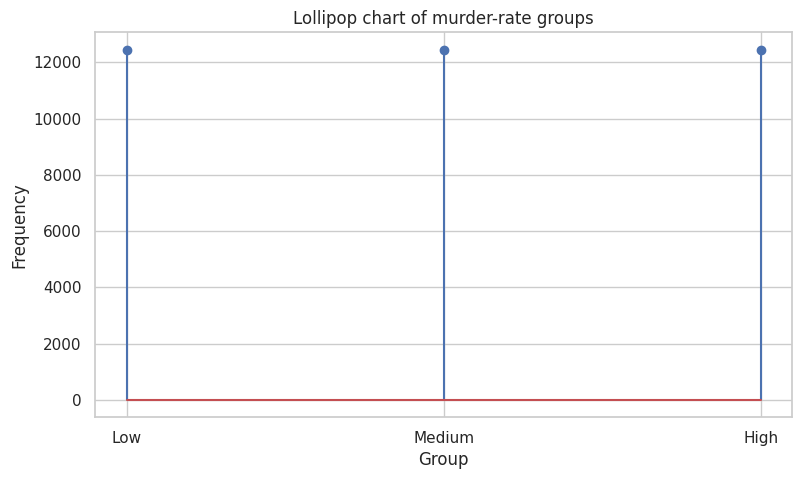

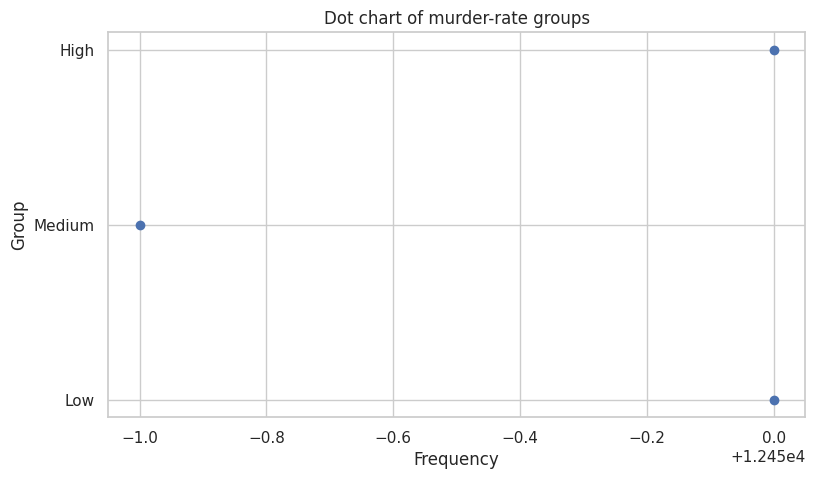

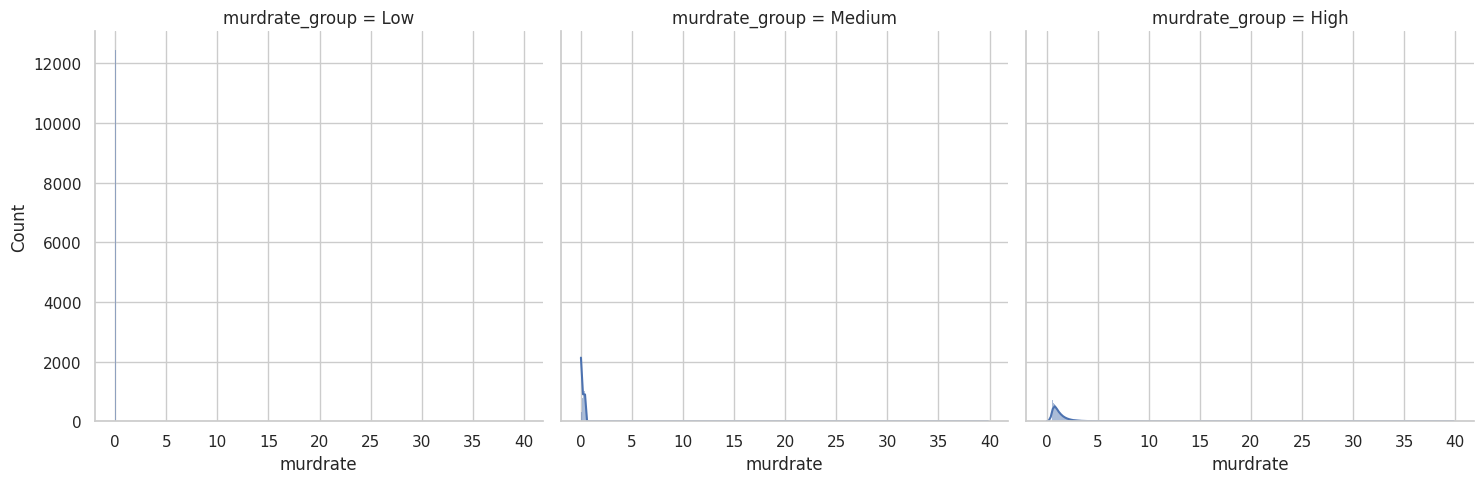

In [ ]:

# Create murder-rate groups safely
df["murdrate_group"] = pd.qcut(
    df[target_num].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

# Frequency distribution
freq = df["murdrate_group"].value_counts().sort_index()
relative_freq = df["murdrate_group"].value_counts(normalize=True).sort_index()

frequency_table = pd.DataFrame({
    "Frequency": freq,
    "Proportion": relative_freq,
    "Percentage": relative_freq * 100
})

display(frequency_table)

# Vertical bar chart
freq.plot(
    kind="bar",
    title="Frequency by murder-rate group",
    xlabel="Murder-rate group",
    ylabel="Count"
)
plt.show()

# Horizontal bar chart
freq.plot(
    kind="barh",
    title="Horizontal frequency bar chart",
    xlabel="Count",
    ylabel="Murder-rate group"
)
plt.show()

# Percentage bar chart
(relative_freq * 100).plot(
    kind="bar",
    title="Percentage bar chart",
    ylabel="Percentage (%)"
)
plt.show()

# Pie chart
freq.plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Pie chart of murder-rate groups"
)
plt.ylabel("")
plt.show()

# Lollipop chart
plt.figure()
plt.stem(freq.index.astype(str), freq.values)
plt.title("Lollipop chart of murder-rate groups")
plt.xlabel("Group")
plt.ylabel("Frequency")
plt.show()

# Dot chart
plt.figure()
plt.scatter(freq.values, freq.index.astype(str))
plt.title("Dot chart of murder-rate groups")
plt.xlabel("Frequency")
plt.ylabel("Group")
plt.show()

# Faceted distributions
sns.displot(
    data=df,
    x=target_num,
    col="murdrate_group",
    col_wrap=3,
    kde=True
)
plt.show()


Contingency table:


murdrate_group,Low,Medium,High
period_group,,,
1980-1985,4146,4280,4756
1986-1991,4326,4471,4385
1992-1996,3978,3698,3309


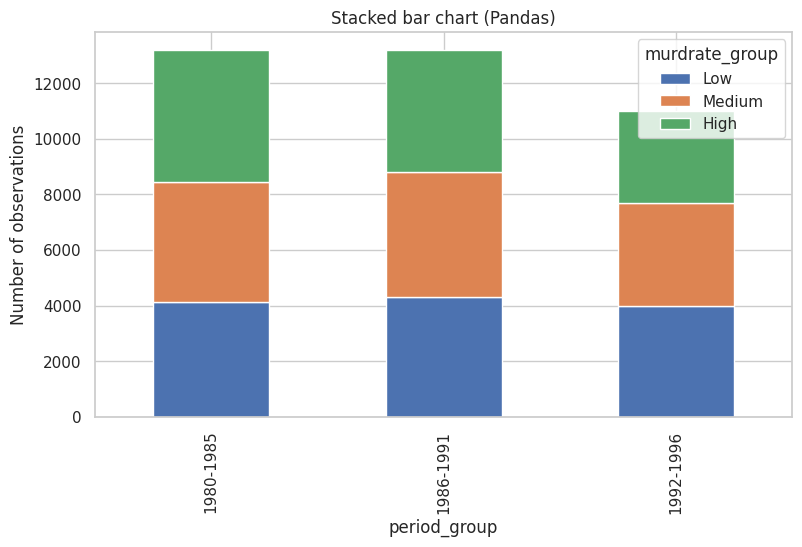

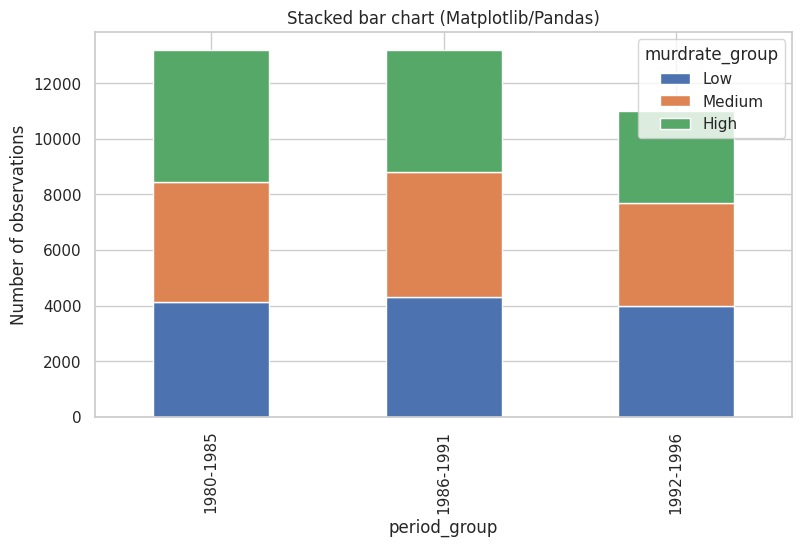

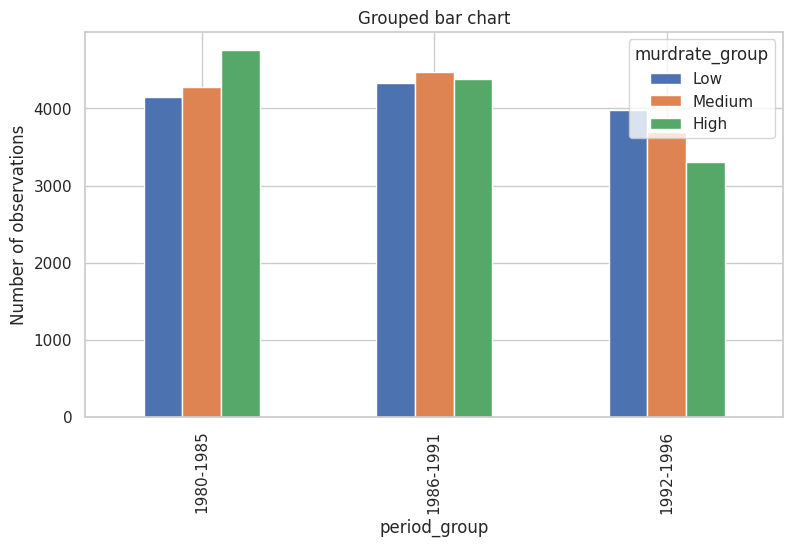

In [ ]:
if "year" in df.columns:
    df["period_group"] = pd.cut(df["year"], bins=[1979, 1985, 1991, 1997],
                                labels=["1980-1985", "1986-1991", "1992-1996"])
else:
    df["period_group"] = pd.qcut(np.arange(len(df)), 3, labels=["Group A", "Group B", "Group C"])

ct = pd.crosstab(df["period_group"], df["murdrate_group"])
print("Contingency table:")
display(ct)

ct.plot(kind="bar", stacked=True, title="Stacked bar chart (Pandas)")
plt.ylabel("Number of observations")
plt.show()

ct.plot(kind="bar", stacked=True)
plt.title("Stacked bar chart (Matplotlib/Pandas)")
plt.ylabel("Number of observations")
plt.show()

ct.plot(kind="bar", stacked=False, title="Grouped bar chart")
plt.ylabel("Number of observations")
plt.show()

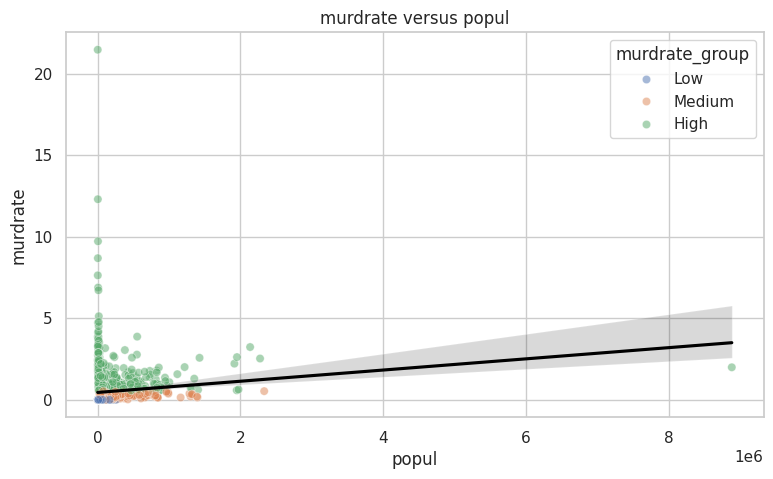

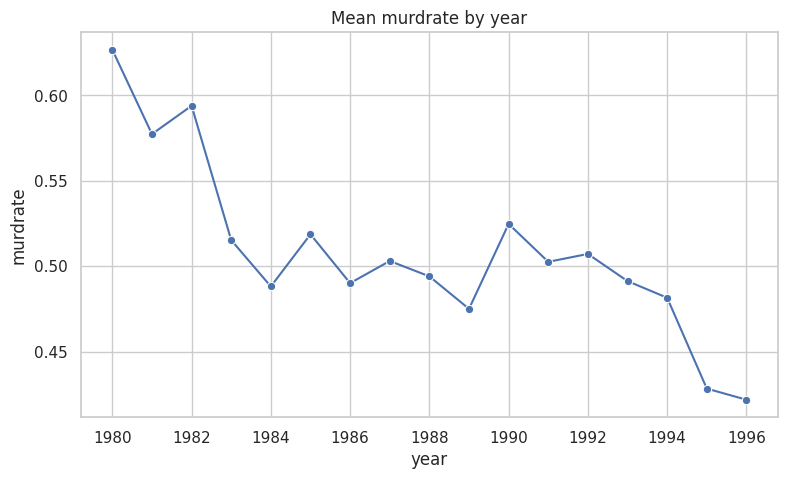

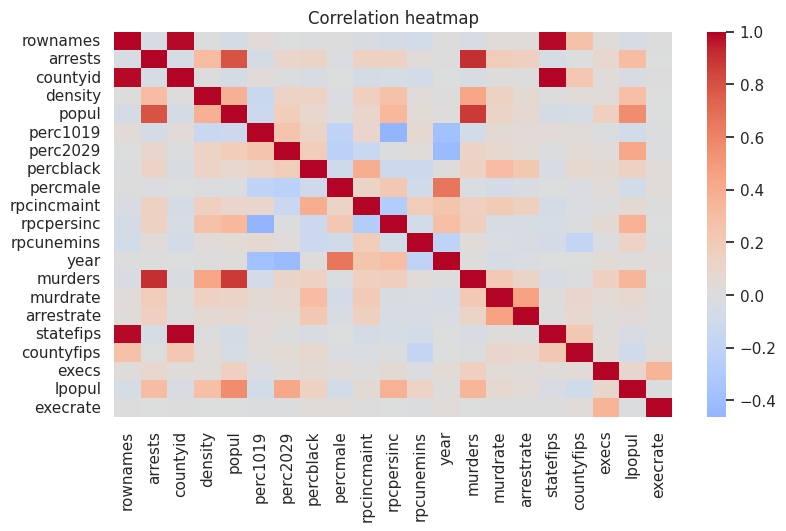

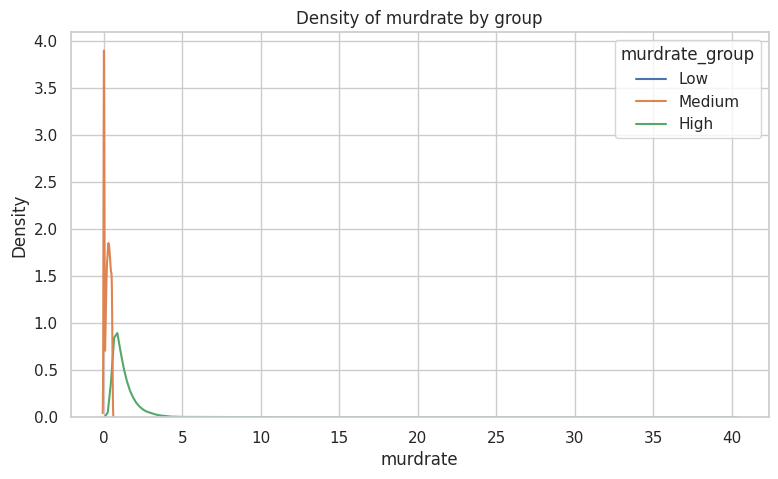

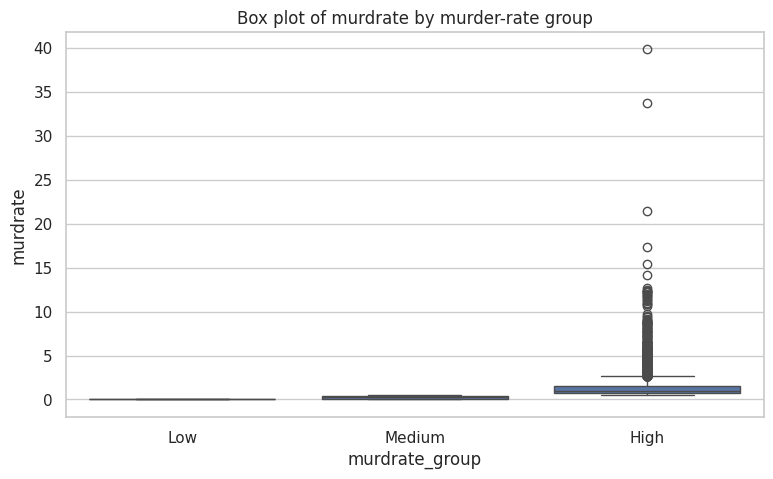

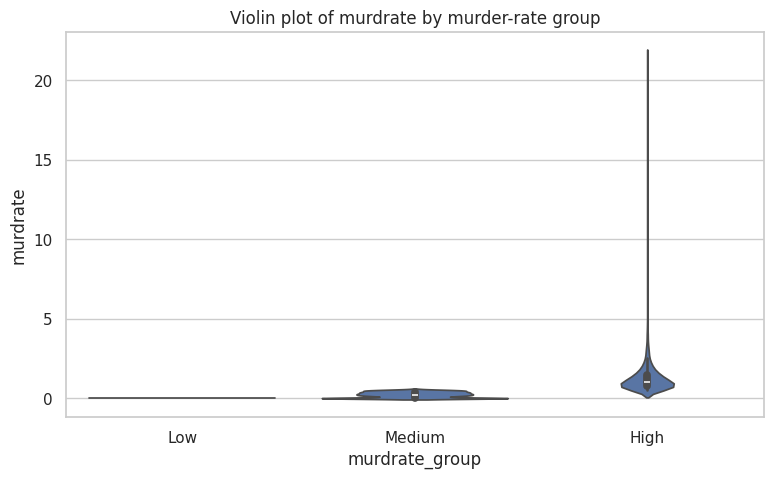

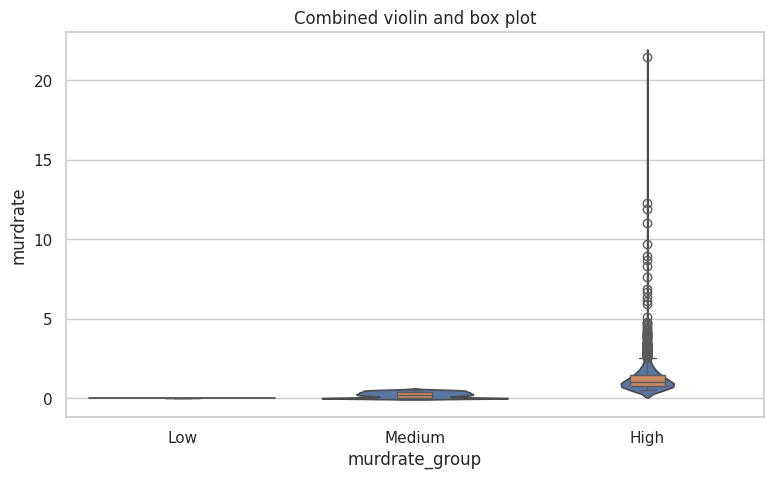

In [ ]:
x_var = "popul" if "popul" in df.columns else df.select_dtypes(include=np.number).columns[0]
y_var = "murdrate" if "murdrate" in df.columns else df.select_dtypes(include=np.number).columns[1]

sample_df = df[[x_var, y_var, "murdrate_group"]].dropna().sample(min(3000, df[[x_var, y_var, "murdrate_group"]].dropna().shape[0]), random_state=42)
plt.figure()
sns.scatterplot(data=sample_df, x=x_var, y=y_var, hue="murdrate_group", alpha=0.5)
sns.regplot(data=sample_df, x=x_var, y=y_var, scatter=False, color="black")
plt.title(f"{y_var} versus {x_var}")
plt.show()

# Year trend (mean murder rate by year)
if "year" in df.columns:
    annual = df.groupby("year", as_index=False)[target_num].mean()
    sns.lineplot(data=annual, x="year", y=target_num, marker="o")
    plt.title(f"Mean {target_num} by year")
    plt.show()

plt.figure()
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

plt.figure()
sns.kdeplot(data=df, x=target_num, hue="murdrate_group", common_norm=False)
plt.title(f"Density of {target_num} by group")
plt.show()

plt.figure()
sns.boxplot(data=df, x="murdrate_group", y=target_num)
plt.title(f"Box plot of {target_num} by murder-rate group")
plt.show()

plt.figure()
sns.violinplot(data=df.sample(min(5000, len(df)), random_state=42), x="murdrate_group", y=target_num)
plt.title(f"Violin plot of {target_num} by murder-rate group")
plt.show()

plt.figure()
sns.violinplot(data=df.sample(min(5000, len(df)), random_state=42), x="murdrate_group", y=target_num, inner=None)
sns.boxplot(data=df.sample(min(5000, len(df)), random_state=42), x="murdrate_group", y=target_num, width=0.15)
plt.title("Combined violin and box plot")
plt.show()


Numerical variables used: ['popul', 'murdrate', 'arrestrate', 'density', 'percblack']


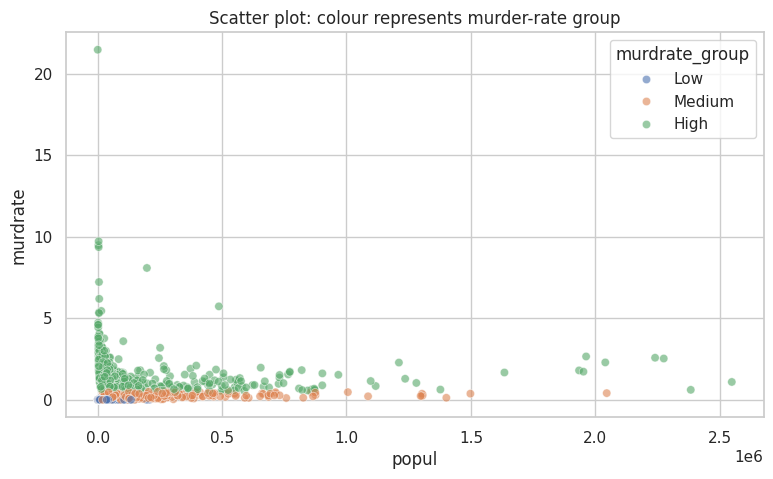

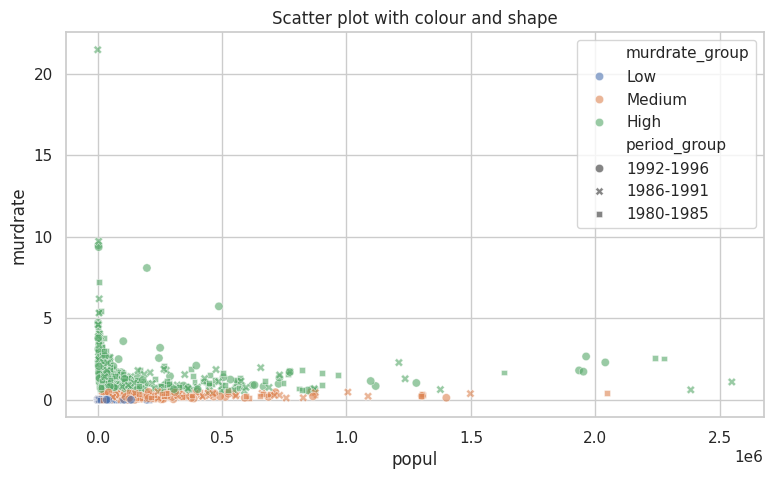

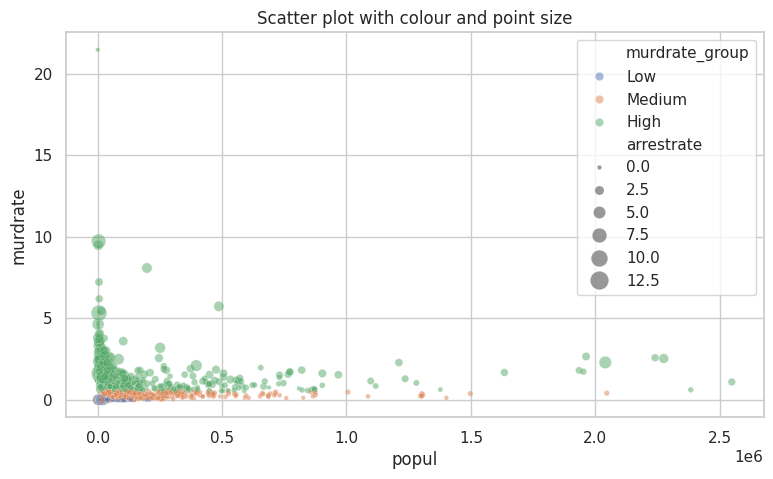

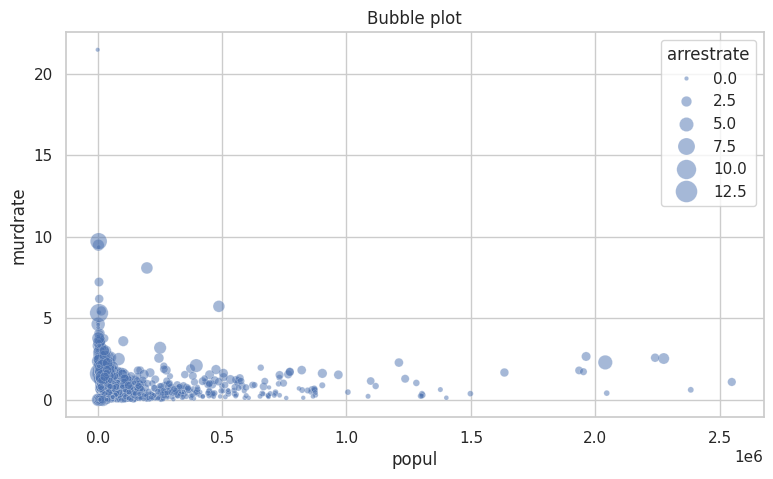

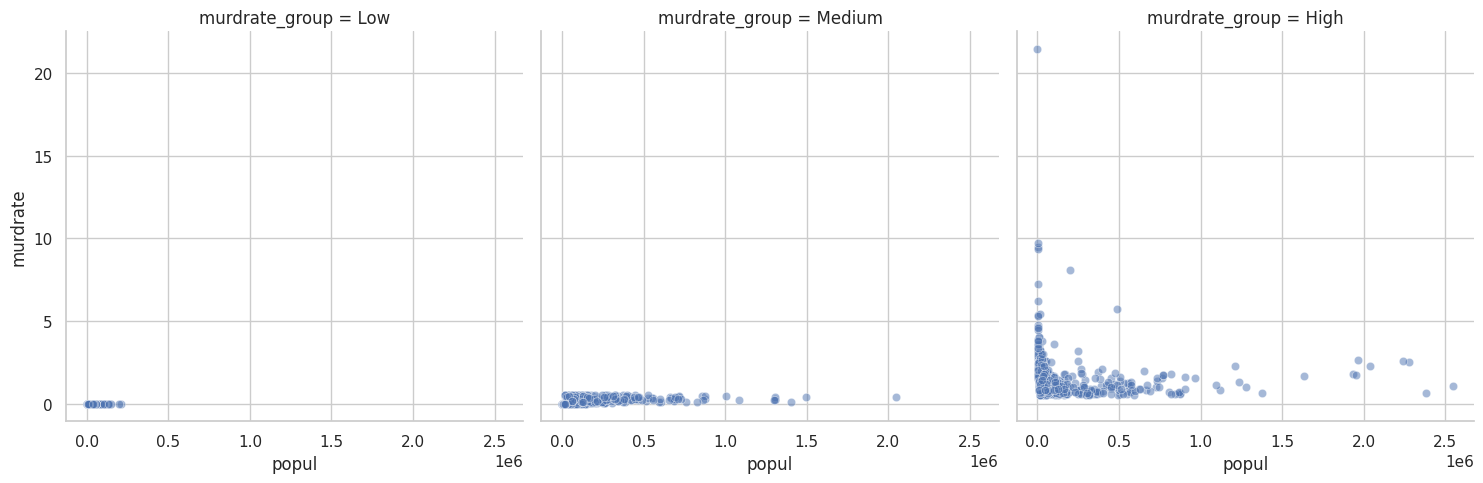

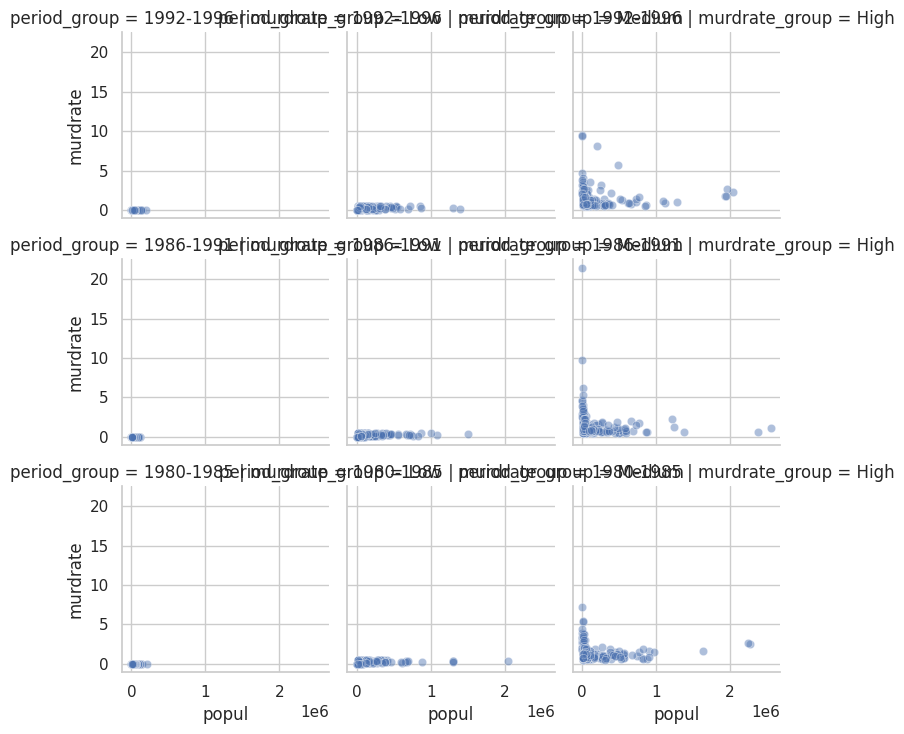

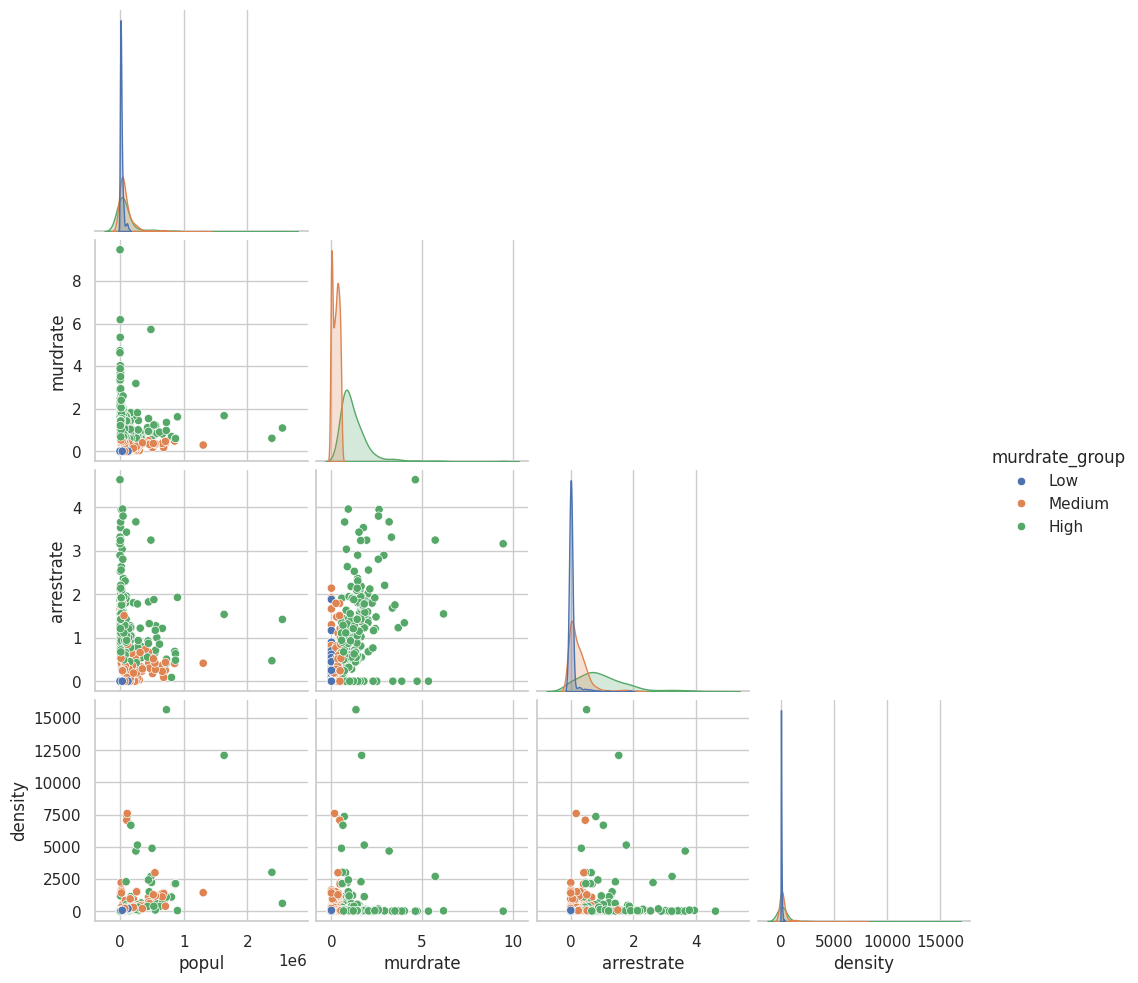

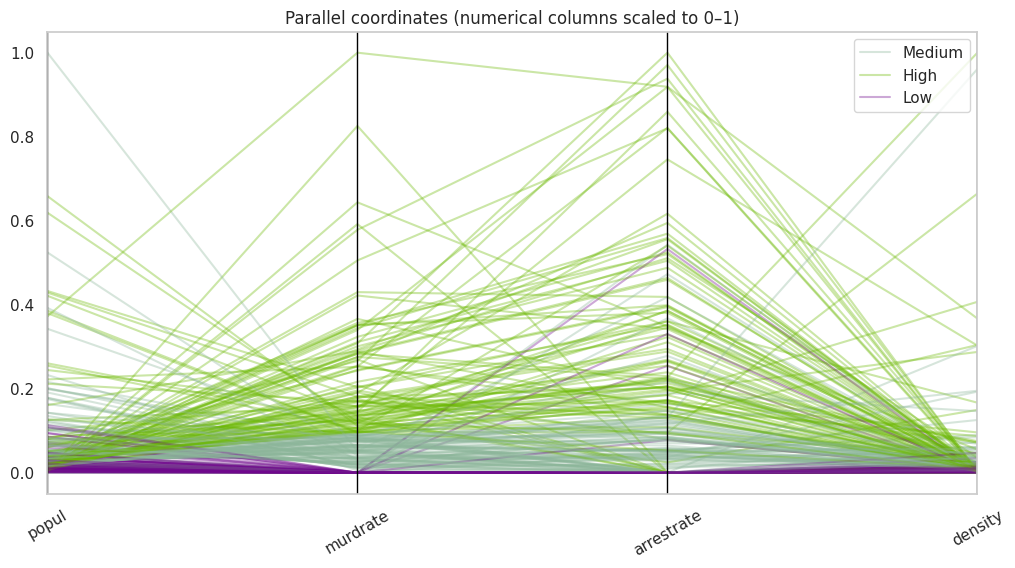

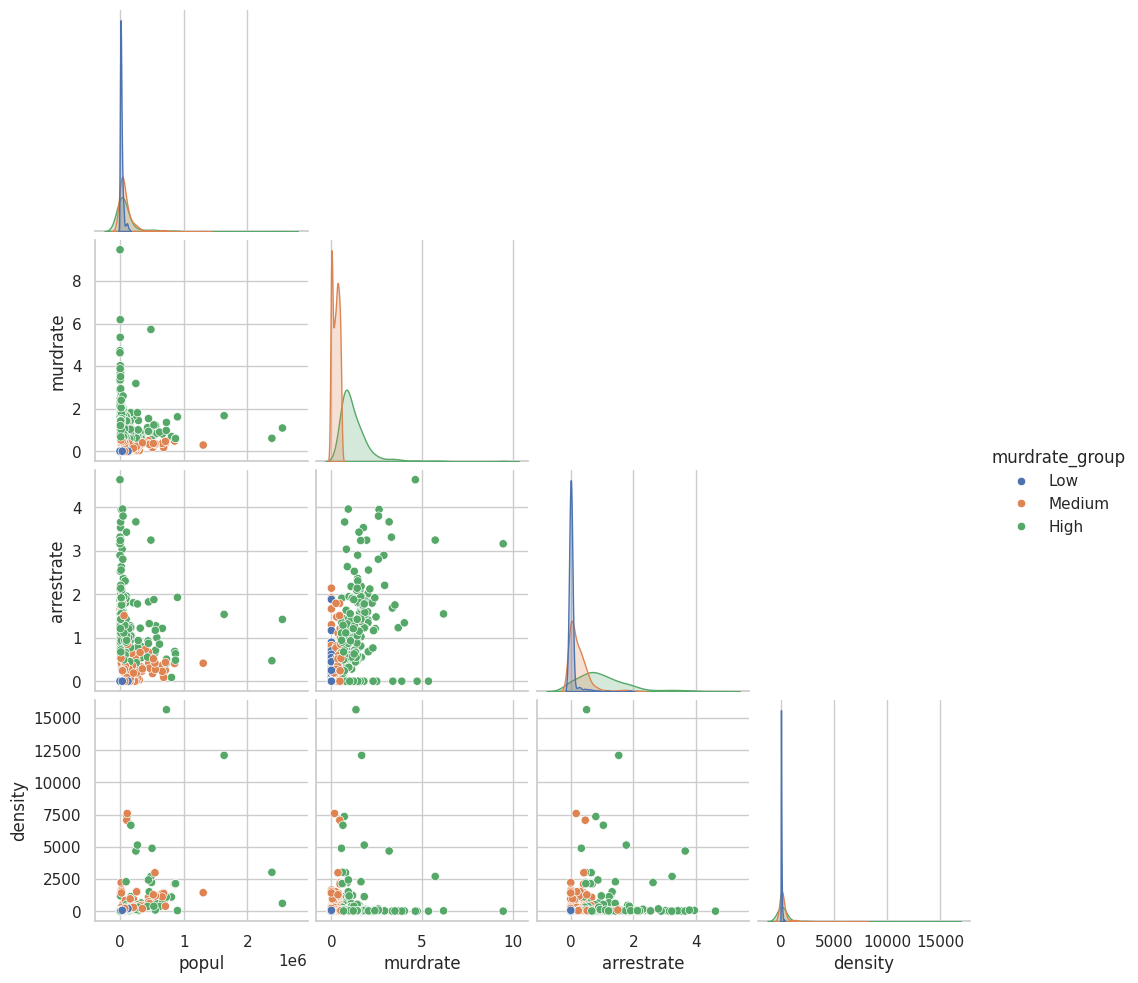

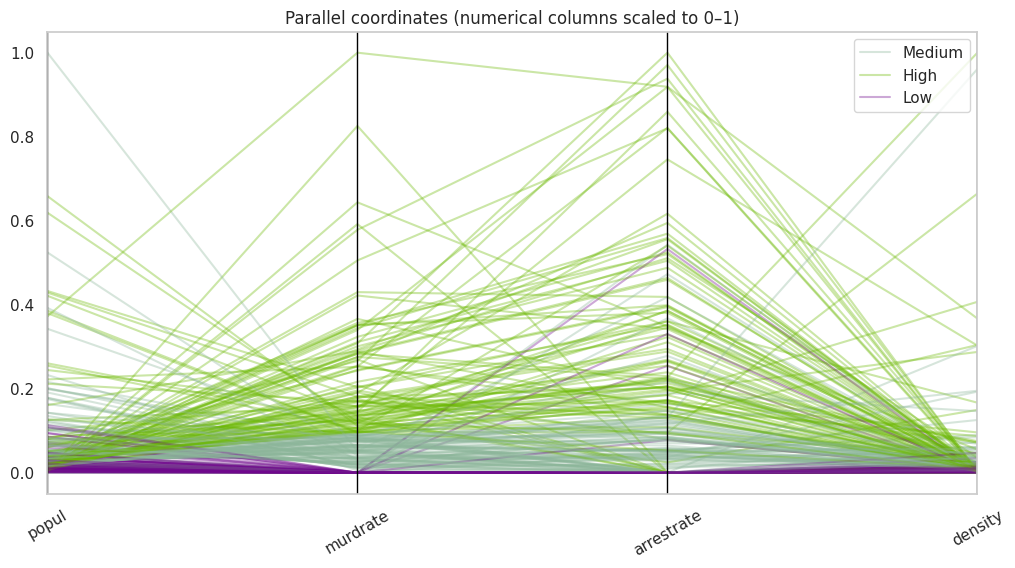

In [ ]:

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

selected = [
    c for c in ["popul", "murdrate", "arrestrate", "density", "percblack"]
    if c in numeric_cols
]

if len(selected) < 4:
    selected = numeric_cols[:min(5, len(numeric_cols))]

print("Numerical variables used:", selected)

cat_var = "murdrate_group"

# Create period_group before creating plot_df
if "period_group" not in df.columns:
    df["period_group"] = "All"

df["period_group"] = df["period_group"].astype(str)

# Include period_group in plot_df
required_cols = list(dict.fromkeys(selected + [cat_var, "period_group"]))
plot_df = df[required_cols].dropna()

plot_df = plot_df.sample(
    n=min(3000, len(plot_df)),
    random_state=42
)

# Three variables: x, y and colour
if len(selected) >= 2:
    sns.scatterplot(
        data=plot_df,
        x=selected[0],
        y=selected[1],
        hue=cat_var,
        alpha=0.6
    )
    plt.title("Scatter plot: colour represents murder-rate group")
    plt.show()

    # Four variables: colour and shape
    sns.scatterplot(
        data=plot_df,
        x=selected[0],
        y=selected[1],
        hue=cat_var,
        style="period_group",
        alpha=0.6
    )
    plt.title("Scatter plot with colour and shape")
    plt.show()

# Four variables: colour and point size
if len(selected) >= 3:
    sns.scatterplot(
        data=plot_df,
        x=selected[0],
        y=selected[1],
        hue=cat_var,
        size=selected[2],
        sizes=(10, 180),
        alpha=0.5
    )
    plt.title("Scatter plot with colour and point size")
    plt.show()

    # Bubble plot
    sns.scatterplot(
        data=plot_df,
        x=selected[0],
        y=selected[1],
        size=selected[2],
        sizes=(10, 250),
        alpha=0.5,
        legend="brief"
    )
    plt.title("Bubble plot")
    plt.show()

# Facet wrap
sns.relplot(
    data=plot_df,
    x=selected[0],
    y=selected[1],
    col=cat_var,
    col_wrap=3,
    kind="scatter",
    alpha=0.5
)
plt.show()

# Facet grid
sns.relplot(
    data=plot_df,
    x=selected[0],
    y=selected[1],
    row="period_group",
    col=cat_var,
    kind="scatter",
    alpha=0.45,
    height=2.5
)
plt.show()

# Pair plot
pair_cols = selected[:min(4, len(selected))]

pair_df = df[pair_cols + [cat_var]].dropna()
pair_df = pair_df.sample(
    n=min(1000, len(pair_df)),
    random_state=42
)

sns.pairplot(pair_df, hue=cat_var, corner=True)
plt.show()

# Parallel-coordinate plot
from pandas.plotting import parallel_coordinates

parallel_df = df[pair_cols + [cat_var]].dropna()
parallel_df = parallel_df.sample(
    n=min(300, len(parallel_df)),
    random_state=42
).copy()

for c in pair_cols:
    span = parallel_df[c].max() - parallel_df[c].min()
    parallel_df[c] = (
        parallel_df[c] - parallel_df[c].min()
    ) / (span if span else 1)

plt.figure(figsize=(12, 6))
parallel_coordinates(parallel_df, cat_var, alpha=0.35)
plt.title("Parallel coordinates (numerical columns scaled to 0–1)")
plt.xticks(rotation=30)
plt.show()

pair_cols = selected[:min(4, len(selected))]
sns.pairplot(df[pair_cols + [cat_var]].dropna().sample(min(1000, len(df)), random_state=42),
             hue=cat_var, corner=True)
plt.show()

from pandas.plotting import parallel_coordinates
parallel_df = df[pair_cols + [cat_var]].dropna().sample(min(300, df[pair_cols + [cat_var]].dropna().shape[0]), random_state=42).copy()
for c in pair_cols:
    span = parallel_df[c].max() - parallel_df[c].min()
    parallel_df[c] = (parallel_df[c] - parallel_df[c].min()) / (span if span else 1)
plt.figure(figsize=(12, 6))
parallel_coordinates(parallel_df, cat_var, alpha=0.35)
plt.title("Parallel coordinates (numerical columns scaled to 0–1)")
plt.xticks(rotation=30)
plt.show()



,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


,Passengers
Month,
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


Start: 1949-01-01 00:00:00 End: 1960-12-01 00:00:00
Frequency: monthly
Shape: (144, 1)


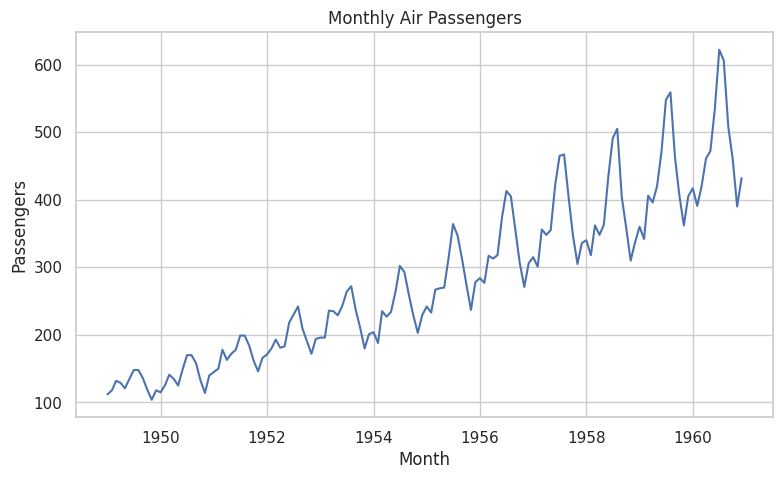

In [ ]:
air_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
air = pd.read_csv(air_url)
air.columns = ["Month", "Passengers"]
air["Month"] = pd.to_datetime(air["Month"])
air = air.set_index("Month").asfreq("MS")
display(air.head())
display(air.tail())
print("Start:", air.index.min(), "End:", air.index.max())
print("Frequency: monthly")
print("Shape:", air.shape)

plt.figure()
plt.plot(air.index, air["Passengers"])
plt.title("Monthly Air Passengers")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.show()


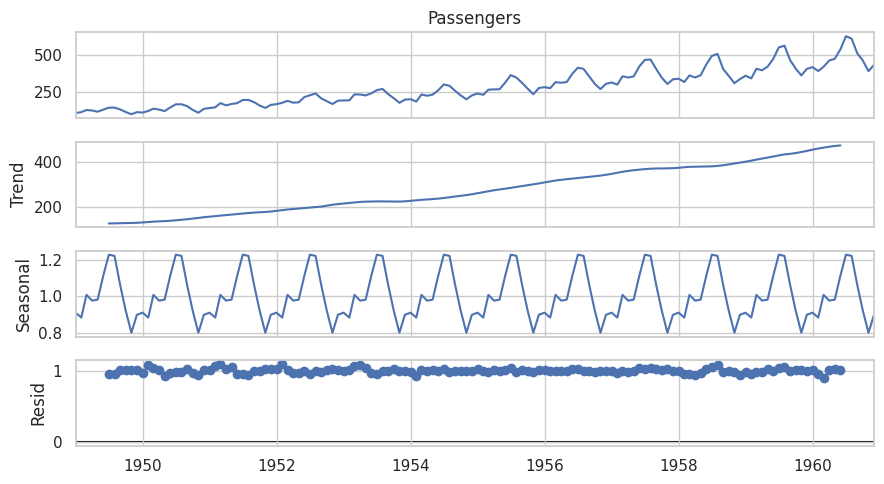

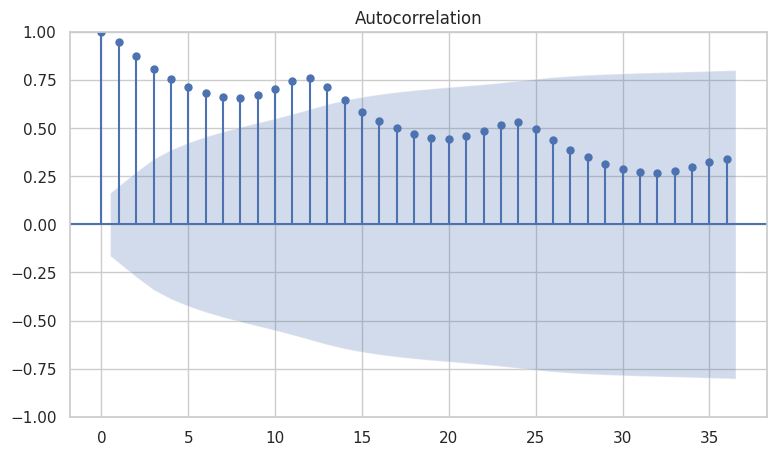

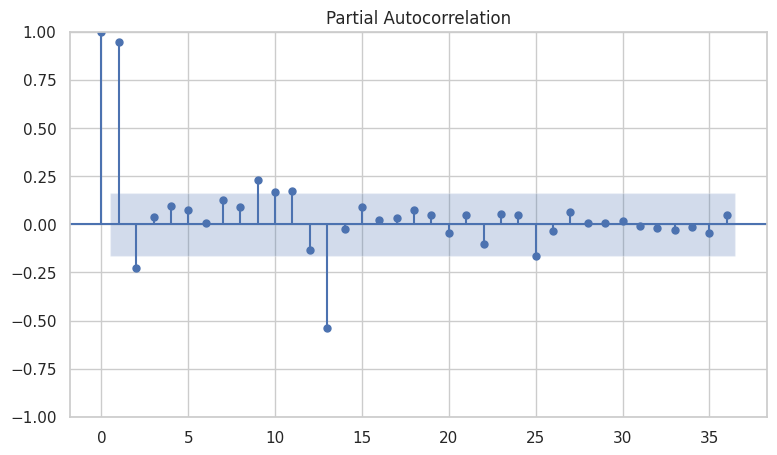

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(2, 1, 2)   Log Likelihood                 128.890
Date:                Mon, 19 Oct 2026   AIC                           -247.780
Time:                        10:03:02   BIC                           -232.965
Sample:                    01-01-1949   HQIC                          -241.760
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2431      0.166      1.469      0.142      -0.081       0.568
ar.L2          0.2677      0.199      1.344      0.179      -0.123       0.658
ma.L1         -0.0867      0.118     -0.732      0.4

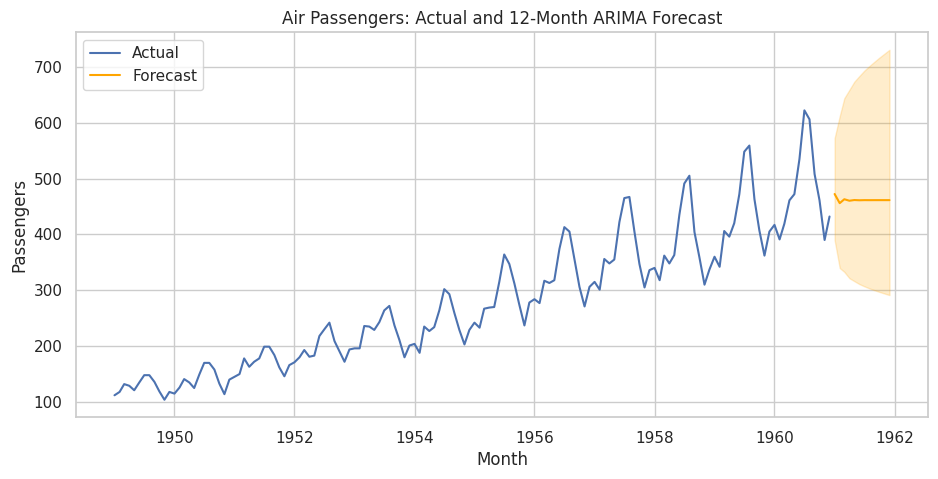

,Forecast passengers
1961-01-01,472
1961-02-01,456
1961-03-01,463
1961-04-01,460
1961-05-01,461
1961-06-01,461
1961-07-01,461
1961-08-01,461
1961-09-01,461
1961-10-01,461


In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

decomposition = seasonal_decompose(air["Passengers"], model="multiplicative", period=12)
decomposition.plot()
plt.show()

plot_acf(air["Passengers"], lags=36)
plt.show()
plot_pacf(air["Passengers"], lags=36, method="ywm")
plt.show()

# Fit ARIMA model; log transformation helps stabilize growth/variance
log_passengers = np.log(air["Passengers"])
model = ARIMA(log_passengers, order=(2, 1, 2))
model_fit = model.fit()
print(model_fit.summary())

forecast_log = model_fit.get_forecast(steps=12)
forecast = np.exp(forecast_log.predicted_mean)
conf = np.exp(forecast_log.conf_int())
future_dates = pd.date_range(air.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
forecast.index = future_dates
conf.index = future_dates

plt.figure(figsize=(11, 5))
plt.plot(air.index, air["Passengers"], label="Actual")
plt.plot(forecast.index, forecast, label="Forecast", color="orange")
plt.fill_between(forecast.index, conf.iloc[:, 0], conf.iloc[:, 1], alpha=0.2, color="orange")
plt.title("Air Passengers: Actual and 12-Month ARIMA Forecast")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.show()
display(pd.DataFrame({"Forecast passengers": forecast.round(0).astype(int)}))


,mean,median,min,max,range,variance,std_dev,IQR,skewness,kurtosis
rownames,18675.000000,18675.000000,1.000000,3.734900e+04,3.734800e+04,1.162488e+08,10781.871939,18674.000000,0.000000,-1.200000
arrests,6.782250,1.000000,0.000000,2.391000e+03,2.391000e+03,2.512882e+03,50.128657,3.000000,26.877130,890.391738
countyid,32921.927173,36065.000000,1001.000000,5.604500e+04,5.504400e+04,2.411297e+08,15528.352966,27944.000000,-0.380673,-0.958365
density,252.241067,44.240000,0.050000,5.405877e+04,5.405872e+04,2.768126e+06,1663.768484,88.918420,20.856906,540.340365
popul,89343.541219,28792.000000,85.000000,9.127751e+06,9.127666e+06,7.390487e+10,271854.498963,53336.000000,16.393979,445.681958
perc1019,15.582640,15.420000,7.080000,3.048458e+01,2.340458e+01,3.894305e+00,1.973399,2.410000,0.486134,2.004580
perc2029,14.584615,14.270000,5.617244,4.052000e+01,3.490276e+01,1.366343e+01,3.696407,3.898300,1.423938,4.779396
percblack,7.823194,1.450000,0.000000,8.627934e+01,8.627934e+01,1.765462e+02,13.287067,8.540000,2.328830,5.522335
percmale,43.350958,41.810000,35.150000,7.804000e+01,4.289000e+01,1.382064e+01,3.717612,4.970000,1.130372,0.921928
rpcincmaint,165.450844,145.147500,5.490000,1.306496e+03,1.301006e+03,9.504098e+03,97.488961,113.630000,1.570885,4.631863


,Frequency
murdrate_group,
Low,12450
High,12450
Medium,12449


,Relative frequency
murdrate_group,
Low,0.333342
High,0.333342
Medium,0.333315


murdrate_group,Low,Medium,High
period_group,,,
1980-1985,4146,4280,4756
1986-1991,4326,4471,4385
1992-1996,3978,3698,3309


Row percentages:


murdrate_group,Low,Medium,High
period_group,,,
1980-1985,31.451980,32.468518,36.079502
1986-1991,32.817478,33.917463,33.265058
1992-1996,36.213018,33.664087,30.122895


Column percentages:


murdrate_group,Low,Medium,High
period_group,,,
1980-1985,33.301205,34.380272,38.200803
1986-1991,34.746988,35.914531,35.220884
1992-1996,31.951807,29.705197,26.578313


,mean,median,std
murdrate_group,,,
Low,0.000000,0.000000,0.000000
Medium,0.230280,0.241044,0.175016
High,1.294304,1.012351,1.090286


Pearson correlation: 0.11871229369466765
Spearman correlation: 0.3287251528623689


mean       std  count
period_group murdrate_group                           
1980-1985    Low             0.000000  0.000000   4146
             Medium          0.236175  0.174809   4280
             High            1.321187  1.150468   4756
1986-1991    Low             0.000000  0.000000   4326
             Medium          0.231660  0.174770   4471
             High            1.261553  0.966406   4385
1992-1996    Low             0.000000  0.000000   3978
             Medium          0.221790  0.175275   3698
             High            1.299067  1.153590   3309

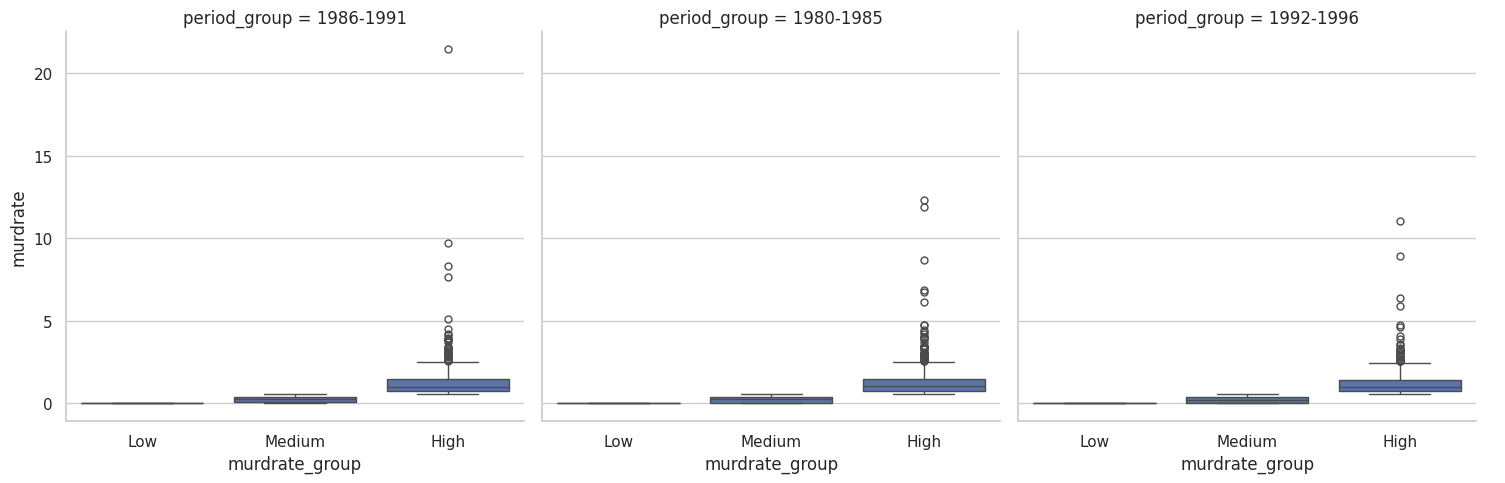

Correlation matrix for category: Low


,popul,murdrate
popul,1.0,NaN
murdrate,NaN,NaN


Correlation matrix for category: Medium


,popul,murdrate
popul,1.000000,0.181745
murdrate,0.181745,1.000000


Correlation matrix for category: High


,popul,murdrate
popul,1.000000,0.029449
murdrate,0.029449,1.000000


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
rownames,1.000000,-0.042613,9.874345e-01,0.002649,-0.060608,0.039989,-0.005638,-0.013782,0.001813,-0.037363,...,-0.078843,4.543780e-04,-0.039936,0.030421,0.021541,9.871205e-01,2.707525e-01,0.020697,-0.046460,0.011430
arrests,-0.042613,1.000000,-4.606477e-02,0.311693,0.792039,-0.055317,0.097915,0.119305,-0.020348,0.143854,...,0.025419,1.588388e-03,0.906295,0.172154,0.154936,-4.613004e-02,-1.239912e-03,0.083742,0.297718,-0.000749
countyid,0.987434,-0.046065,1.000000e+00,0.010010,-0.061212,0.036127,-0.007710,-0.028573,-0.001444,-0.056774,...,-0.072340,3.461751e-13,-0.042459,0.013849,0.006024,9.999771e-01,2.318303e-01,0.018656,-0.037362,0.009194
density,0.002649,0.311693,1.000971e-02,1.000000,0.380315,-0.135204,0.126121,0.129959,-0.020912,0.164865,...,0.034143,3.468035e-03,0.433851,0.137594,0.061293,9.837386e-03,2.703860e-02,0.022459,0.280124,-0.000814
popul,-0.060608,0.792039,-6.121241e-02,0.380315,1.000000,-0.119220,0.185030,0.084739,-0.013728,0.099992,...,0.044673,1.499733e-02,0.877110,0.118712,0.064519,-6.096488e-02,-4.954060e-02,0.160758,0.557064,-0.003113
perc1019,0.039989,-0.055317,3.612727e-02,-0.135204,-0.119220,1.000000,0.256169,0.122132,-0.208278,0.098434,...,0.066431,-3.826454e-01,-0.073315,0.046229,0.036857,3.596605e-02,3.141287e-02,-0.019806,-0.078025,-0.011402
perc2029,-0.005638,0.097915,-7.710277e-03,0.126121,0.185030,0.256169,1.000000,0.174507,-0.223615,-0.146472,...,0.032846,-4.282845e-01,0.117278,0.074479,0.042230,-8.012452e-03,4.163893e-02,0.026597,0.424437,-0.011871
percblack,-0.013782,0.119305,-2.857313e-02,0.129959,0.084739,0.122132,0.174507,1.000000,-0.104799,0.391590,...,-0.129342,1.190266e-02,0.139215,0.312546,0.227672,-2.916773e-02,7.887198e-02,0.047100,0.148421,0.020806
percmale,0.001813,-0.020348,-1.443695e-03,-0.020912,-0.013728,-0.208278,-0.223615,-0.104799,1.000000,0.113756,...,-0.088569,6.603317e-01,-0.025080,-0.064556,-0.037630,-1.293116e-03,-2.195738e-02,0.028234,-0.082901,0.029087
rpcincmaint,-0.037363,0.143854,-5.677418e-02,0.164865,0.099992,0.098434,-0.146472,0.391590,0.113756,1.000000,...,0.189517,2.453886e-01,0.157738,0.199870,0.152835,-5.667931e-02,-2.659639e-02,0.005941,0.056256,0.007829


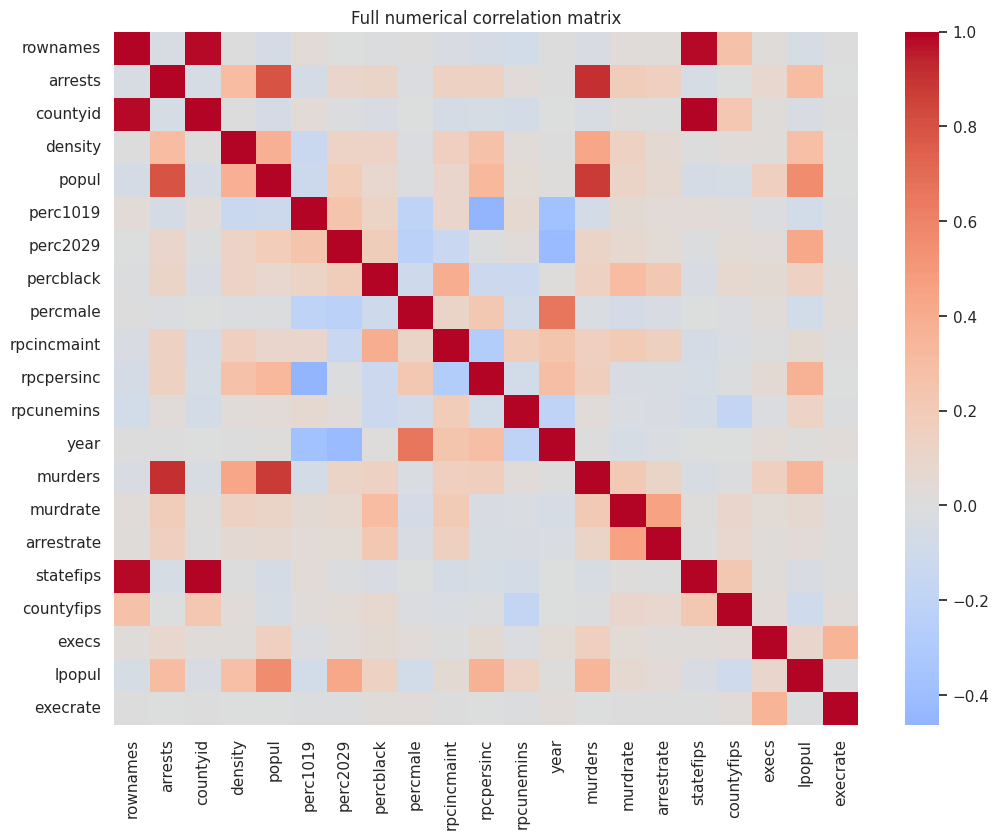

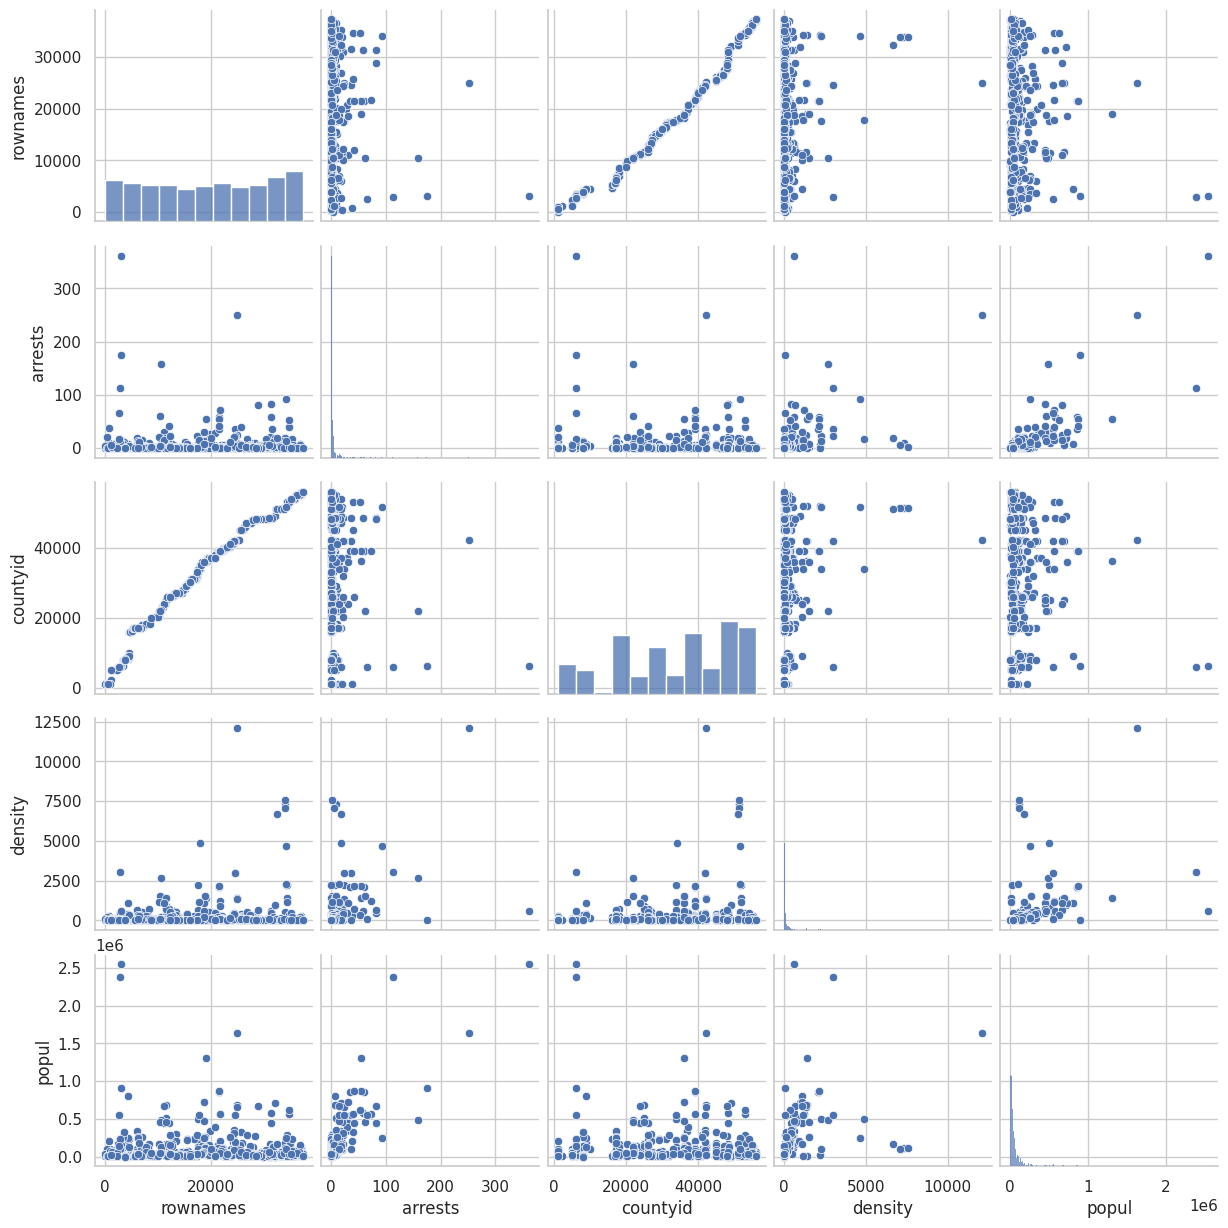

In [ ]:
# 1D: summary statistics, skewness, kurtosis
numeric_df = df.select_dtypes(include=np.number)
summary = pd.DataFrame({
    "mean": numeric_df.mean(),
    "median": numeric_df.median(),
    "min": numeric_df.min(),
    "max": numeric_df.max(),
    "range": numeric_df.max() - numeric_df.min(),
    "variance": numeric_df.var(),
    "std_dev": numeric_df.std(),
    "IQR": numeric_df.quantile(0.75) - numeric_df.quantile(0.25),
    "skewness": numeric_df.skew(),
    "kurtosis": numeric_df.kurt()
})
display(summary)

# Categorical frequency and relative frequency
display(df["murdrate_group"].value_counts().to_frame("Frequency"))
display(df["murdrate_group"].value_counts(normalize=True).to_frame("Relative frequency"))

# 2D: cross tabulation and row/column proportions
ct2 = pd.crosstab(df["period_group"], df["murdrate_group"])
display(ct2)
print("Row percentages:")
display(pd.crosstab(df["period_group"], df["murdrate_group"], normalize="index") * 100)
print("Column percentages:")
display(pd.crosstab(df["period_group"], df["murdrate_group"], normalize="columns") * 100)

# Grouped numerical summary
display(df.groupby("murdrate_group")[target_num].agg(["mean", "median", "std"]))

# Pearson and Spearman correlations
corr_pair = df[[x_var, y_var]].dropna()
print("Pearson correlation:", corr_pair[x_var].corr(corr_pair[y_var], method="pearson"))
print("Spearman correlation:", corr_pair[x_var].corr(corr_pair[y_var], method="spearman"))

# Summary across two categorical variables and one numerical variable
display(df.groupby(["period_group", "murdrate_group"], observed=True)[target_num].agg(["mean", "std", "count"]))
sns.catplot(data=df.sample(min(5000, len(df)), random_state=42), x="murdrate_group", y=target_num,
            col="period_group", kind="box", col_wrap=3)
plt.show()

# Per-category correlation matrix for two numerical variables
for category, group in df.groupby("murdrate_group", observed=True):
    print("Correlation matrix for category:", category)
    display(group[[x_var, y_var]].corr())

# Full correlation matrix, heatmap and pairs plot
corr_matrix = numeric_df.corr()
display(corr_matrix)
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Full numerical correlation matrix")
plt.show()

pair_cols7 = numeric_df.columns[:min(5, len(numeric_df.columns))].tolist()
sns.pairplot(df[pair_cols7].dropna().sample(min(800, len(df)), random_state=42))
plt.show()


In [ ]:
# Select numerical features and standardize
cluster_features = [c for c in ["murdrate", "arrestrate", "density", "perc1019",
                                "perc2029", "percblack", "percmale", "rpcpersinc"] if c in df.columns]
cluster_data = df[cluster_features].replace([np.inf, -np.inf], np.nan).dropna()

# Sample rows to make the hierarchical part practical
cluster_sample = cluster_data.sample(min(1500, len(cluster_data)), random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_sample)

print("Features used:", cluster_features)
print("Clustering sample shape:", X_scaled.shape)

# K-Means for k=2
kmeans2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels2 = kmeans2.fit_predict(X_scaled)
cluster_sample_result = cluster_sample.copy()
cluster_sample_result["Cluster"] = labels2
display(cluster_sample_result.head())
print("K-Means cluster counts:")
display(cluster_sample_result["Cluster"].value_counts().sort_index())

centers_original_scale = scaler.inverse_transform(kmeans2.cluster_centers_)
display(pd.DataFrame(centers_original_scale, columns=cluster_features).rename_axis("Cluster center"))


Features used: ['murdrate', 'arrestrate', 'density', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcpersinc']
Clustering sample shape: (1500, 8)


,murdrate,arrestrate,density,perc1019,perc2029,percblack,percmale,rpcpersinc,Cluster
2770,0.085752,0.171505,448.7126,9.941259,10.81679,3.793251,49.51379,28904.59,0
2541,2.462084,1.477250,20.1500,13.510000,16.74000,3.320000,45.64000,9003.13,1
36477,0.000000,0.000000,30.6200,14.270000,11.92000,0.060000,42.49000,10005.52,0
13146,0.000000,0.000000,65.6900,15.070000,20.85000,0.190000,40.04000,9859.07,0
13103,0.265439,0.189599,621.9796,16.352940,14.67575,0.621886,50.22107,13664.23,0


K-Means cluster counts:


,count
Cluster,
0,1149
1,351


,murdrate,arrestrate,density,perc1019,perc2029,percblack,percmale,rpcpersinc
Cluster center,,,,,,,,
0,0.234650,0.195584,171.184348,15.385332,14.297700,3.357516,43.902681,11538.293571
1,1.293408,1.377677,598.728616,16.071435,15.564074,23.529769,42.729657,10086.277433


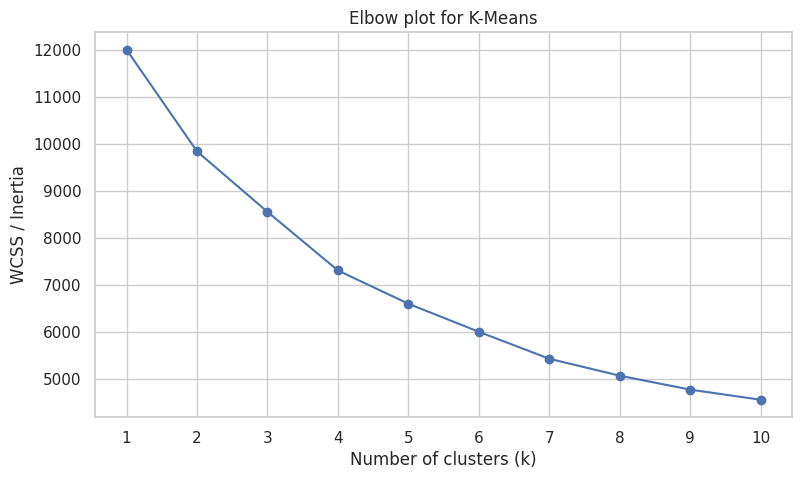

Final cluster counts (k=3):


,count
Elbow_Cluster,
0,431
1,266
2,803


In [ ]:
# WCSS (inertia) for k = 1 to 10 and elbow plot
wcss = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure()
plt.plot(list(k_values), wcss, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow plot for K-Means")
plt.show()

# Set k based on the elbow plot after inspecting it; k=3 is a practical starting choice
chosen_k = 3
kmeans_final = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
final_labels = kmeans_final.fit_predict(X_scaled)
cluster_sample_result["Elbow_Cluster"] = final_labels
print("Final cluster counts (k=3):")
display(cluster_sample_result["Elbow_Cluster"].value_counts().sort_index())


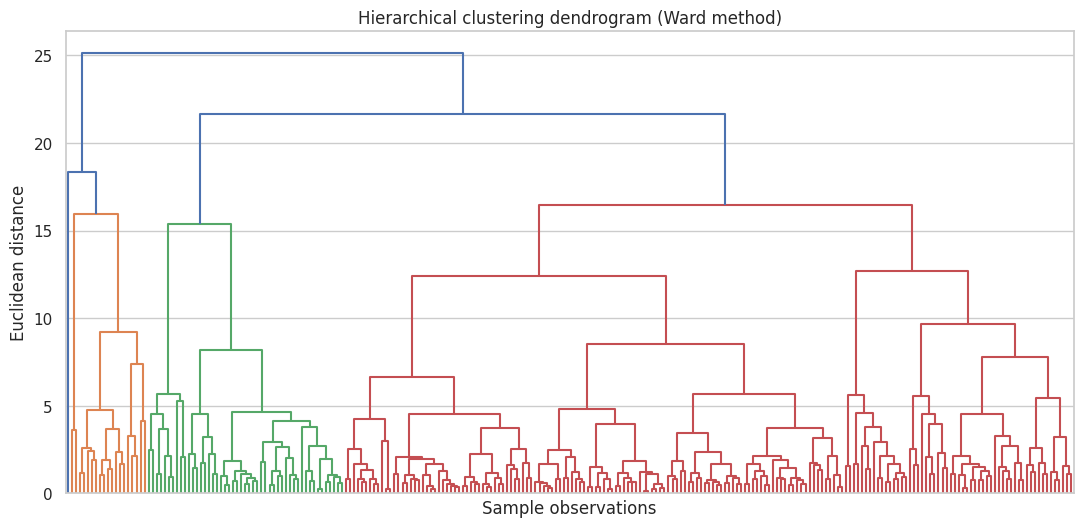

,murdrate,arrestrate,density,perc1019,perc2029,percblack,percmale,rpcpersinc,Cluster
5540,0.000000,0.000000,101.1002,16.45424,18.84766,1.866086,47.47718,12187.82,3
35361,0.364166,0.000000,83.7800,18.07000,14.87000,2.910000,40.98000,8776.31,3
7914,0.265449,0.000000,91.6300,15.67000,15.02000,0.150000,40.69000,11560.27,3
8217,0.461595,0.461595,70.0400,16.42000,15.16000,0.290000,41.21000,8711.84,3
4891,0.000000,0.000000,3.4700,14.90000,10.40000,0.140000,46.27000,11050.07,2
36011,0.146990,0.352775,282.9700,14.27000,24.97000,2.360000,42.41000,13696.35,3
31348,0.000000,0.000000,3.7500,18.39000,17.59000,2.020000,40.71000,10668.91,3
20870,0.000000,0.000000,1.9800,17.32000,9.16000,0.050000,43.40000,10268.66,3
1366,0.000000,0.000000,33.5700,13.03000,12.36000,0.040000,42.78000,9944.39,3
34633,0.000000,0.000000,18.3200,13.46000,12.73000,0.250000,42.94000,10937.14,3


Number of samples in each hierarchical cluster:


,count
Cluster,
1,20
2,49
3,181


In [ ]:
# Hierarchical clustering: Euclidean distance + Ward linkage
# Use a smaller sample for a readable and responsive dendrogram
hier_sample = cluster_data.sample(min(250, len(cluster_data)), random_state=24)
X_hier = StandardScaler().fit_transform(hier_sample)

Z = linkage(X_hier, method="ward", metric="euclidean")
plt.figure(figsize=(13, 6))
dendrogram(Z, no_labels=True)
plt.title("Hierarchical clustering dendrogram (Ward method)")
plt.xlabel("Sample observations")
plt.ylabel("Euclidean distance")
plt.show()

hier_labels = fcluster(Z, t=3, criterion="maxclust")
hier_result = hier_sample.copy()
hier_result["Cluster"] = hier_labels
display(hier_result.head(10))
print("Number of samples in each hierarchical cluster:")
display(hier_result["Cluster"].value_counts().sort_index())


In [ ]:
# Libraries are already imported in your previous cells
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (37349, 23)
Columns: ['rownames', 'arrests', 'countyid', 'density', 'popul', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcincmaint', 'rpcpersinc', 'rpcunemins', 'year', 'murders', 'murdrate', 'arrestrate', 'statefips', 'countyfips', 'execs', 'lpopul', 'execrate', 'murdrate_group', 'period_group']


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate,murdrate_group,period_group
0,1,2.0,1001,54.05,32216,20.63,15.28,22.33,40.25,167.67,...,2,0.620810,0.620810,1,1,0,10.38022,0.0,High,1980-1985
1,2,3.0,1001,53.66,31984,20.19,15.55,22.07,40.36,167.99,...,1,0.312656,0.937969,1,1,0,10.37299,0.0,Medium,1980-1985
2,3,2.0,1001,53.75,32036,19.66,15.73,21.80,40.42,166.63,...,3,0.936446,0.624298,1,1,0,10.37462,0.0,High,1980-1985
3,4,7.0,1001,53.78,32056,19.10,15.88,21.53,40.47,176.53,...,7,2.183679,2.183679,1,1,0,10.37524,0.0,High,1980-1985
4,5,3.0,1001,53.91,32128,18.54,15.92,21.26,40.51,166.25,...,2,0.622510,0.933765,1,1,0,10.37748,0.0,High,1980-1985


In [ ]:
print("Total number of rows:", df.shape[0])
print("Total number of columns:", df.shape[1])

Total number of rows: 37349
Total number of columns: 23


In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_data_pca = df.select_dtypes(include=np.number).copy()

# Handle missing and infinite values
numeric_data_pca = numeric_data_pca.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Remove constant columns
numeric_data_pca = numeric_data_pca.loc[
    :, numeric_data_pca.nunique() > 1
]

if numeric_data_pca.shape[1] < 2:
    raise ValueError("PCA requires at least two varying numeric columns.")

# Standardize the data
pca_scaler = StandardScaler()

data_scaled = pd.DataFrame(
    pca_scaler.fit_transform(numeric_data_pca),
    columns=numeric_data_pca.columns,
    index=numeric_data_pca.index
)

print("Shape of standardized data:", data_scaled.shape)
display(data_scaled.head())

Shape of standardized data: (36842, 21)


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,...,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
0,-1.734276,-0.095408,-2.056987,-0.119685,-0.211665,2.565723,0.191012,1.094394,-0.840760,0.018618,...,-0.784220,-1.645012,-0.112590,0.133083,0.088661,-2.053886,-0.9173,-0.061024,0.017106,-0.035883
1,-1.734183,-0.075460,-2.056987,-0.119918,-0.212513,2.342550,0.263936,1.074771,-0.811085,0.021902,...,-0.505458,-1.440629,-0.133648,-0.229656,0.345973,-2.053886,-0.9173,-0.061024,0.011643,-0.035883
2,-1.734091,-0.095408,-2.056987,-0.119864,-0.212323,2.073728,0.312552,1.054392,-0.794898,0.007943,...,0.013728,-1.236247,-0.091532,0.504631,0.091491,-2.053886,-0.9173,-0.061024,0.012875,-0.035883
3,-1.733998,0.004333,-2.056987,-0.119846,-0.212250,1.789689,0.353066,1.034014,-0.781409,0.109558,...,0.029026,-1.031864,-0.007301,1.972796,1.356620,-2.053886,-0.9173,-0.061024,0.013343,-0.035883
4,-1.733905,-0.075460,-2.056987,-0.119769,-0.211986,1.505650,0.363869,1.013636,-0.770618,0.004042,...,-0.572693,-0.827482,-0.112590,0.135084,0.342562,-2.053886,-0.9173,-0.061024,0.015036,-0.035883


In [ ]:
from sklearn.decomposition import PCA

pca_model = PCA()
pca_array = pca_model.fit_transform(data_scaled)

variance_percent = pca_model.explained_variance_ratio_ * 100
cumulative_percent = np.cumsum(variance_percent)

pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(variance_percent))
    ],
    "Standard Deviation": np.sqrt(pca_model.explained_variance_),
    "Variance Explained (%)": variance_percent,
    "Cumulative Variance (%)": cumulative_percent
})

display(pca_summary)

,Principal Component,Standard Deviation,Variance Explained (%),Cumulative Variance (%)
0,PC1,1.904543,17.272308,17.272308
1,PC2,1.744905,14.498140,31.770448
2,PC3,1.559307,11.577970,43.348418
3,PC4,1.377073,9.029894,52.378313
4,PC5,1.166145,6.475505,58.853818
5,PC6,1.150338,6.301148,65.154966
6,PC7,1.072583,5.478106,70.633071
7,PC8,1.015437,4.909922,75.542994
8,PC9,0.935474,4.167084,79.710078
9,PC10,0.891201,3.781987,83.492065


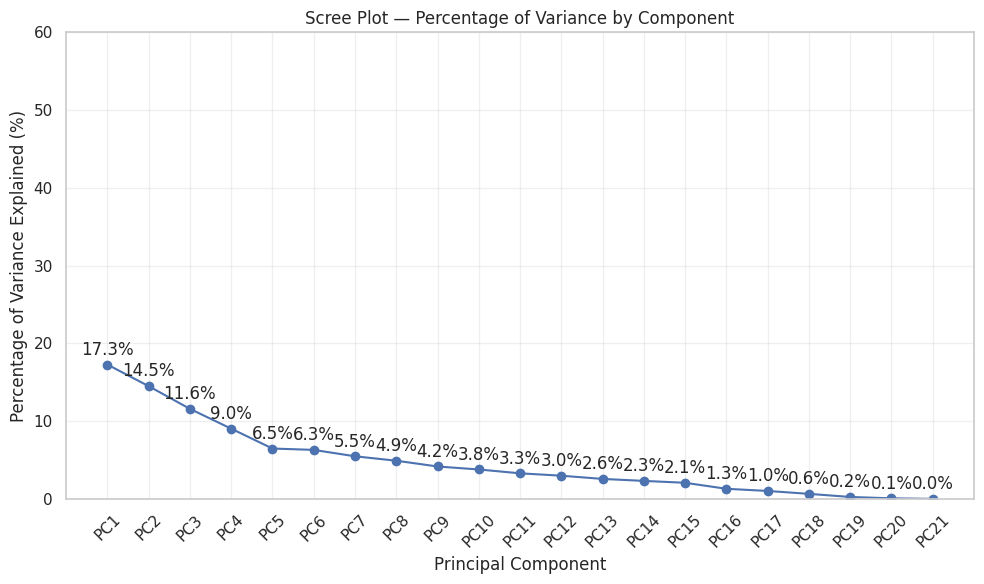

In [ ]:
components = np.arange(1, len(variance_percent) + 1)

plt.figure(figsize=(10, 6))
plt.plot(components, variance_percent, marker="o")
plt.xticks(components, [f"PC{i}" for i in components], rotation=45)
plt.ylim(0, 60)

plt.xlabel("Principal Component")
plt.ylabel("Percentage of Variance Explained (%)")
plt.title("Scree Plot — Percentage of Variance by Component")
plt.grid(True, alpha=0.3)

for x, y in zip(components, variance_percent):
    if 0 <= y <= 60:
        plt.annotate(
            f"{y:.1f}%", (x, y),
            textcoords="offset points",
            xytext=(0, 7), ha="center"
        )

plt.tight_layout()
plt.show()

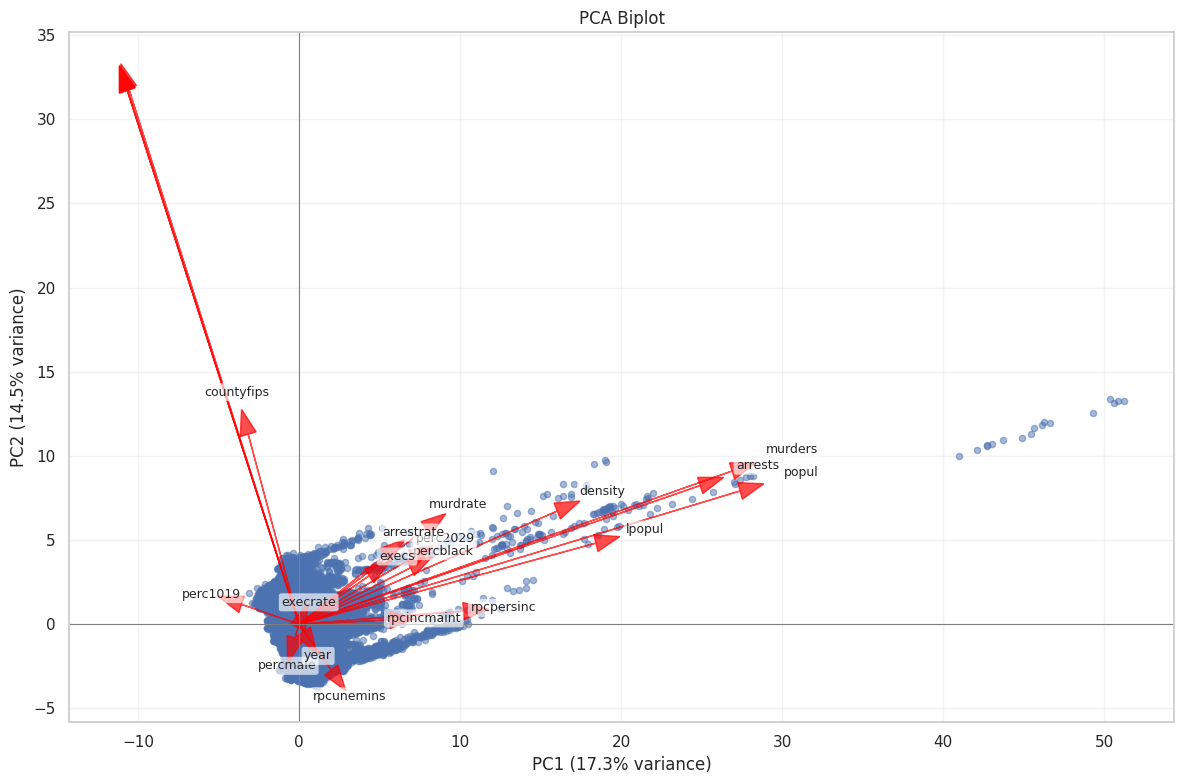

In [ ]:
scores_2d = pca_array[:, :2]
loadings_2d = pca_model.components_.T[:, :2]

plt.figure(figsize=(12, 8))
plt.scatter(
    scores_2d[:, 0],
    scores_2d[:, 1],
    alpha=0.5,
    s=20
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)

score_range = max(np.max(np.abs(scores_2d)), 1)
loading_range = max(np.max(np.abs(loadings_2d)), 1e-9)
arrow_scale = score_range * 0.65 / loading_range

for i, variable in enumerate(data_scaled.columns):
    x = loadings_2d[i, 0] * arrow_scale
    y = loadings_2d[i, 1] * arrow_scale

    plt.arrow(
        0, 0, x, y,
        color="red",
        alpha=0.7,
        head_width=score_range * 0.02,
        length_includes_head=True
    )

    plt.annotate(
        variable, (x * 1.08, y * 1.08),
        fontsize=9,
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            alpha=0.65,
            ec="none"
        )
    )

plt.xlabel(f"PC1 ({variance_percent[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({variance_percent[1]:.1f}% variance)")
plt.title("PCA Biplot")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
pca_scores = pd.DataFrame(
    pca_array,
    columns=[
        f"PC{i+1}" for i in range(pca_array.shape[1])
    ],
    index=data_scaled.index
)

display(pca_scores.head(6))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21
0,0.632233,-3.068213,-3.142723,0.447987,0.477679,0.063329,-0.550344,-1.147787,-0.469252,-0.713421,...,0.427910,-0.160877,1.029619,0.660743,-0.109999,-0.569140,-0.222222,0.047165,0.267691,-4.462755e-15
1,0.606425,-3.115485,-3.041382,0.460868,0.328715,0.176568,-0.446305,-1.050109,-0.471128,-0.590328,...,0.299071,-0.543982,0.710716,0.638891,-0.275296,-0.415676,-0.143186,0.019024,0.273098,-4.906605e-15
2,0.755402,-3.098418,-2.967792,0.601484,0.237817,0.158427,-0.211775,-0.605683,-0.389827,-0.412762,...,0.353377,0.199118,0.628115,0.565158,-0.376875,-0.192659,-0.069576,-0.001492,0.273850,-5.128703e-15
3,1.237697,-2.827262,-3.109709,1.638147,0.686084,-0.535373,-0.267599,0.586510,-0.849498,-0.289873,...,0.395745,0.404781,0.645117,0.254665,-0.375080,-0.032669,-0.025383,-0.023144,0.258260,-5.128724e-15
4,0.798515,-3.102763,-2.321202,0.594816,0.528832,-0.143959,-0.309560,-0.764090,-0.398021,-0.694537,...,0.207556,-0.259067,0.427044,0.307015,-0.252920,-0.056572,-0.054609,0.003860,0.273444,-4.906753e-15
5,0.756418,-3.166995,-2.012237,0.344693,0.484189,-0.087993,-0.233810,-0.877749,-0.218593,-0.749422,...,0.208709,0.093543,0.379463,0.290180,-0.318149,0.091260,-0.017606,-0.001034,0.280480,-5.128921e-15


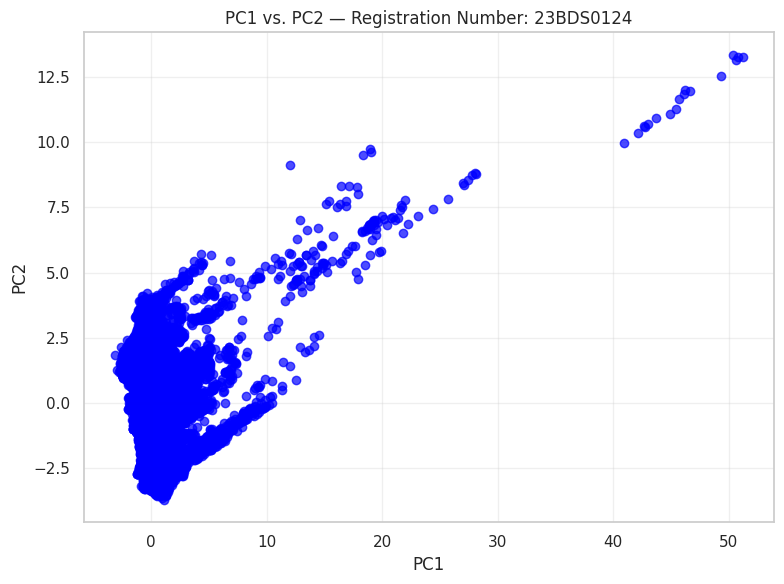

In [ ]:
registration_number = "23BDS0124"

plt.figure(figsize=(8, 6))

plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    marker="o",
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(
    f"PC1 vs. PC2 — Registration Number: {registration_number}"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()